# Multimodal Alzheimer's classification (ADNI): fMRI + SNP + clinical
Three-class (CN / MCI / AD) three-branch MLP and HAMF-style attention model. Run top to bottom (Restart & Run All).

In [61]:
# 1. Setup
import os, re, json, random, warnings, copy, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score)
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED=42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_everything()
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

Device: cpu


In [62]:
# ============================================================
# CONFIGURATION: ACTUAL KAGGLE DATA PATHS
# ============================================================

from pathlib import Path

# ----------------------------
# fMRI FEATURES
# ----------------------------
FMRI_PATH = Path(
    "/kaggle/input/datasets/ananya2323/fmri-data/"
    "MAYOADIRL_MRI_FMRI_NFQ_18Nov2026.csv"
)

# ----------------------------
# SNP / GENETIC DATA (PLINK)
# ----------------------------
SNP_BED_PATH = Path(
    "/kaggle/input/datasets/ananya2323/snpdata/"
    "WGS_Omni25_BIN_wo_ConsentsIssues.bed"
)

SNP_BIM_PATH = Path(
    "/kaggle/input/datasets/ananya2323/snpdata/"
    "WGS_Omni25_BIN_wo_ConsentsIssues.bim"
)

SNP_FAM_PATH = Path(
    "/kaggle/input/datasets/ananya2323/snpdata/"
    "WGS_Omni25_BIN_wo_ConsentsIssues.fam"
)

# ----------------------------
# CLINICAL DATA
# ----------------------------
CLINICAL_PATH = Path(
    "/kaggle/input/datasets/ananya2323/adnimerge/"
    "ADNIMERGE2/ADNIMERGE2/data/"
    "ADSP_PHC_MERGED_DATADIC_20260521.rda"
)

# ----------------------------
# IDENTIFIERS / TARGET
# ----------------------------
ID_COL = "RID"

# Update later if your actual clinical table uses a different label column
LABEL_COL = "ARM"

# ----------------------------
# EXPECTED CLASSES
# ----------------------------
EXPECTED_CLASSES = ["CN", "EMCI", "LMCI", "AD"]

# ----------------------------
# VERIFY FILES
# ----------------------------
paths_to_check = {
    "fMRI": FMRI_PATH,
    "SNP BED": SNP_BED_PATH,
    "SNP BIM": SNP_BIM_PATH,
    "SNP FAM": SNP_FAM_PATH,
    "Clinical": CLINICAL_PATH,
}

print("VERIFYING DATA PATHS\n")

for name, path in paths_to_check.items():
    if path.exists():
        print(f"[FOUND] {name}: {path}")
    else:
        print(f"[MISSING] {name}: {path}")
        raise FileNotFoundError(f"{name} file not found!")

print("\nAll configured paths exist.")

VERIFYING DATA PATHS

[FOUND] fMRI: /kaggle/input/datasets/ananya2323/fmri-data/MAYOADIRL_MRI_FMRI_NFQ_18Nov2026.csv
[FOUND] SNP BED: /kaggle/input/datasets/ananya2323/snpdata/WGS_Omni25_BIN_wo_ConsentsIssues.bed
[FOUND] SNP BIM: /kaggle/input/datasets/ananya2323/snpdata/WGS_Omni25_BIN_wo_ConsentsIssues.bim
[FOUND] SNP FAM: /kaggle/input/datasets/ananya2323/snpdata/WGS_Omni25_BIN_wo_ConsentsIssues.fam
[FOUND] Clinical: /kaggle/input/datasets/ananya2323/adnimerge/ADNIMERGE2/ADNIMERGE2/data/ADSP_PHC_MERGED_DATADIC_20260521.rda

All configured paths exist.


In [63]:
# ============================================================
# CELL 3: MEMORY-SAFE INITIAL DATA LOADING
# fMRI + SNP METADATA + CLINICAL RDA INSPECTION
# DOES NOT DECODE THE FULL SNP MATRIX
# ============================================================

import os
import subprocess
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

FMRI_PATH = (
    "/kaggle/input/datasets/ananya2323/fmri-data/"
    "MAYOADIRL_MRI_FMRI_NFQ_18Nov2026.csv"
)

SNP_BED_PATH = (
    "/kaggle/input/datasets/ananya2323/snpdata/"
    "WGS_Omni25_BIN_wo_ConsentsIssues.bed"
)

SNP_BIM_PATH = (
    "/kaggle/input/datasets/ananya2323/snpdata/"
    "WGS_Omni25_BIN_wo_ConsentsIssues.bim"
)

SNP_FAM_PATH = (
    "/kaggle/input/datasets/ananya2323/snpdata/"
    "WGS_Omni25_BIN_wo_ConsentsIssues.fam"
)

CLINICAL_PATH = (
    "/kaggle/input/datasets/ananya2323/adnimerge/"
    "ADNIMERGE2/ADNIMERGE2/data/"
    "ADSP_PHC_MERGED_DATADIC_20260521.rda"
)

WORK_DIR = Path("/kaggle/working/adni_processing")
WORK_DIR.mkdir(parents=True, exist_ok=True)

RSCRIPT = "/usr/bin/Rscript"

# Verify paths
for path in [
    FMRI_PATH,
    SNP_BED_PATH,
    SNP_BIM_PATH,
    SNP_FAM_PATH,
    CLINICAL_PATH
]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing file: {path}")

print("All paths verified.")


# ------------------------------------------------------------
# 2. LOAD fMRI
# ------------------------------------------------------------

fmri_raw = pd.read_csv(FMRI_PATH)

print("\n========== fMRI ==========")
print("Shape:", fmri_raw.shape)
print("Columns:", list(fmri_raw.columns))

display(fmri_raw.head(3))


# ------------------------------------------------------------
# 3. LOAD SNP METADATA ONLY
# DO NOT READ OR DECODE THE BED GENOTYPE MATRIX
# ------------------------------------------------------------

# FAM contains participant IDs
fam_raw = pd.read_csv(
    SNP_FAM_PATH,
    sep=r"\s+",
    header=None
)

fam_raw.columns = [
    "FID", "IID", "PAT", "MAT", "SEX", "PHENOTYPE"
]

# BIM contains SNP metadata
bim_raw = pd.read_csv(
    SNP_BIM_PATH,
    sep=r"\s+",
    header=None
)

bim_raw.columns = [
    "CHR", "SNP", "CM", "POS", "A1", "A2"
]

print("\n========== SNP METADATA ==========")
print("Participants in FAM:", fam_raw.shape[0])
print("SNPs in BIM:", bim_raw.shape[0])

display(fam_raw.head(5))
display(bim_raw.head(5))


# ------------------------------------------------------------
# 4. INSPECT CLINICAL RDA WITH R
# NO CSV EXPORT AND NO COPYING OF THE ENTIRE RDA DATAFRAME
# ------------------------------------------------------------

R_SCRIPT_PATH = WORK_DIR / "inspect_clinical.R"

r_script = r'''
args <- commandArgs(trailingOnly=TRUE)
input_file <- args[1]

loaded_objects <- load(input_file)

cat("Objects inside RDA:\n")
print(loaded_objects)

for (obj_name in loaded_objects) {

    obj <- get(obj_name)

    cat("\n====================================\n")
    cat("Object:", obj_name, "\n")
    cat("Class:", class(obj), "\n")

    if (is.data.frame(obj)) {

        cat("Dimensions:", dim(obj), "\n")
        cat("Columns:\n")
        print(names(obj))

        cat("First rows:\n")
        print(utils::head(obj, 3))
    }
}
'''

R_SCRIPT_PATH.write_text(r_script)

result = subprocess.run(
    [
        RSCRIPT,
        str(R_SCRIPT_PATH),
        CLINICAL_PATH
    ],
    capture_output=True,
    text=True
)

print("\n========== CLINICAL INSPECTION ==========")
print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Clinical RDA inspection failed.")


# ------------------------------------------------------------
# 5. INITIAL SUMMARY
# ------------------------------------------------------------

print("\n========== SUMMARY ==========")

print("fMRI rows/columns:", fmri_raw.shape)
print("SNP participants:", fam_raw.shape[0])
print("SNP variants:", bim_raw.shape[0])

print("\nNo full genotype matrix was loaded.")
print("Cell 3 completed safely.")

All paths verified.

========== fMRI ==========
Shape: (2996, 34)
Columns: ['COLPROT', 'RID', 'VISCODE', 'VISCODE2', 'SCANDATE', 'SERIESDATE', 'SERIESTIME', 'MANUFACTURER', 'MANUFACTURERSMODELNAME', 'REPETITIONTIME', 'ECHOTIME', 'SOFTWAREVERSIONS', 'SERIESNUMBER', 'PATIENTSAGE', 'WADDMN_TO_WAVDMN', 'WADDMN_TO_WPDMN', 'WADDMN_TO_WVDMN', 'WAVDMN_TO_WADDMN', 'WAVDMN_TO_WPDMN', 'WAVDMN_TO_WVDMN', 'WPDMN_TO_WADDMN', 'WPDMN_TO_WAVDMN', 'WPDMN_TO_WVDMN', 'WVDMN_TO_WADDMN', 'WVDMN_TO_WAVDMN', 'WVDMN_TO_WPDMN', 'WPDMN_MEDIAN', 'WADDMN_MEDIAN', 'WAVDMN_MEDIAN', 'WVDMN_MEDIAN', 'NFQ', 'OVERALLQC', 'SLICETIMING', 'update_stamp']


,COLPROT,RID,VISCODE,VISCODE2,SCANDATE,SERIESDATE,SERIESTIME,MANUFACTURER,MANUFACTURERSMODELNAME,REPETITIONTIME,...,WVDMN_TO_WAVDMN,WVDMN_TO_WPDMN,WPDMN_MEDIAN,WADDMN_MEDIAN,WAVDMN_MEDIAN,WVDMN_MEDIAN,NFQ,OVERALLQC,SLICETIMING,update_stamp
0,ADNI3,21,init,m144,2018-01-25,2018-01-25,12:05:49,SIEMENS,Prisma_fit,3000.0,...,0.44696,0.71951,0.82791,1.18720,1.01600,1.4657,0.49861,2,43490.525_43489.035_43490.5875_43489.0975_4349...,2023-07-07 09:03:44
1,ADNI3,31,y1,m162,2019-04-24,2019-04-24,10:02:35,SIEMENS,Prisma_fit,607.0,...,0.53266,0.52180,0.56478,0.58680,0.84205,1.5278,0.42029,2,36140.94_36140.5_36140.795_36140.575_36140.867...,2023-07-07 09:03:44
2,ADNI3,56,y1,m156,2019-01-10,2019-01-10,13:05:11,SIEMENS,Prisma_fit,607.0,...,0.32195,0.43148,0.40828,0.84215,0.88865,1.5684,0.44180,2,47082.675_47082.235_47082.5275_47082.3075_4708...,2023-07-07 09:03:44



========== SNP METADATA ==========
Participants in FAM: 812
SNPs in BIM: 2379855


,FID,IID,PAT,MAT,SEX,PHENOTYPE
0,1,067_S_0056,0,0,2,-9
1,2,123_S_0108,0,0,1,-9
2,3,067_S_0059,0,0,2,-9
3,4,024_S_0985,0,0,1,-9
4,5,109_S_2237,0,0,1,-9


,CHR,SNP,CM,POS,A1,A2
0,0,rs2698846,0.0,0,0,G
1,0,rs2542903,0.0,0,0,T
2,0,rs1059667,0.0,0,0,T
3,0,rs35144699,0.0,0,T,A
4,0,rs35425675,0.0,0,A,T



========== CLINICAL INSPECTION ==========
Objects inside RDA:
[1] "ADSP_PHC_MERGED_DATADIC_20260521"

Object: ADSP_PHC_MERGED_DATADIC_20260521 
Class: spec_tbl_df tbl_df tbl data.frame 
Dimensions: 13813 12 
Columns:
 [1] "DS_NAME"        "DS_DSCR"        "VARNAME"        "VARDSCR"       
 [5] "VARTYPE"        "FLD_LEN"        "DECML"          "UNITS"         
 [9] "CODES"          "NOTES"          "VALUE_REQUIRED" "update_stamp"  
First rows:
        DS_NAME
1 ADSP_PHC_COGN
2 ADSP_PHC_COGN
3 ADSP_PHC_COGN
                                                                     DS_DSCR
1 ADSP Phenotype Harmonization Consortium (PHC) - Composite Cognitive Scores
2 ADSP Phenotype Harmonization Consortium (PHC) - Composite Cognitive Scores
3 ADSP Phenotype Harmonization Consortium (PHC) - Composite Cognitive Scores
  VARNAME
1     RID
2    PTID
3  SUBJID
                                                                                                        VARDSCR
1                          

In [64]:
# ============================================================
# CREATE VERIFIED RID MAPPING TABLE
# ============================================================

fam_check = fam_raw.copy()

fam_check["RID"] = (
    fam_check["IID"]
    .astype(str)
    .str.extract(r"_(\d+)$")[0]
    .str.lstrip("0")
)

fmri_check = fmri_raw.copy()

fmri_check["RID"] = (
    fmri_check["RID"]
    .astype(str)
    .str.strip()
    .str.lstrip("0")
)

# Keep participants appearing in both datasets
matched_rids = set(fam_check["RID"]) & set(fmri_check["RID"])

participant_map = (
    fam_check[fam_check["RID"].isin(matched_rids)]
    [["IID", "RID"]]
    .drop_duplicates()
    .sort_values("RID")
    .reset_index(drop=True)
)

print("Matched participants:", len(participant_map))
print(participant_map.head(20))

print("\nMapping table shape:", participant_map.shape)

Matched participants: 324
           IID   RID
0   033_S_1016  1016
1   141_S_1052  1052
2   123_S_0106   106
3   136_S_0107   107
4   003_S_1074  1074
5   033_S_1098  1098
6   003_S_1122  1122
7   002_S_1155  1155
8   032_S_1169  1169
9   013_S_1186  1186
10  023_S_1190  1190
11  941_S_1195  1195
12  027_S_0120   120
13  007_S_1222  1222
14  002_S_1261  1261
15  002_S_1268  1268
16  068_S_0127   127
17  002_S_1280  1280
18  100_S_1286  1286
19  052_S_1352  1352

Mapping table shape: (324, 2)


In [65]:
# ============================================================
# FILTER fMRI TO THE FAM-MATCHED PARTICIPANTS
# ============================================================

matched_rids = set(participant_map["RID"].astype(str))

fmri_filtered = fmri_raw.copy()

fmri_filtered["RID"] = (
    fmri_filtered["RID"]
    .astype(str)
    .str.strip()
    .str.lstrip("0")
)

fmri_filtered = fmri_filtered[
    fmri_filtered["RID"].isin(matched_rids)
].copy()

print("Original fMRI rows:", len(fmri_raw))
print("Filtered fMRI rows:", len(fmri_filtered))
print("Unique matched fMRI participants:", fmri_filtered["RID"].nunique())

print("\nFirst 10 rows:")
display(fmri_filtered.head(10))

Original fMRI rows: 2996
Filtered fMRI rows: 1112
Unique matched fMRI participants: 324

First 10 rows:


,COLPROT,RID,VISCODE,VISCODE2,SCANDATE,SERIESDATE,SERIESTIME,MANUFACTURER,MANUFACTURERSMODELNAME,REPETITIONTIME,...,WVDMN_TO_WAVDMN,WVDMN_TO_WPDMN,WPDMN_MEDIAN,WADDMN_MEDIAN,WAVDMN_MEDIAN,WVDMN_MEDIAN,NFQ,OVERALLQC,SLICETIMING,update_stamp
0,ADNI3,21,init,m144,2018-01-25,2018-01-25,12:05:49,SIEMENS,Prisma_fit,3000.0,...,0.44696,0.719510,0.82791,1.18720,1.01600,1.4657,0.498610,2,43490.525_43489.035_43490.5875_43489.0975_4349...,2023-07-07 09:03:44
1,ADNI3,31,y1,m162,2019-04-24,2019-04-24,10:02:35,SIEMENS,Prisma_fit,607.0,...,0.53266,0.521800,0.56478,0.58680,0.84205,1.5278,0.420290,2,36140.94_36140.5_36140.795_36140.575_36140.867...,2023-07-07 09:03:44
2,ADNI3,56,y1,m156,2019-01-10,2019-01-10,13:05:11,SIEMENS,Prisma_fit,607.0,...,0.32195,0.431480,0.40828,0.84215,0.88865,1.5684,0.441800,2,47082.675_47082.235_47082.5275_47082.3075_4708...,2023-07-07 09:03:44
3,ADNI3,56,init,m144,2017-11-28,2017-11-28,14:30:07,SIEMENS,Prisma_fit,607.0,...,0.19697,0.107880,0.46372,0.63089,0.85704,1.3348,0.075314,2,52182.7425_52183.11_52182.8175_52182.9625_5218...,2023-07-07 09:03:44
4,ADNI3,56,y2,m168,2019-12-03,2019-12-03,13:48:10,SIEMENS,Prisma_fit,607.0,...,0.41094,0.097208,0.49368,0.84506,0.84715,1.6107,0.107840,2,49670.0725_49669.6325_49669.9275_49669.7075_49...,2023-07-07 09:03:44
5,ADNI3,59,init,m144,2017-12-20,2017-12-20,11:20:32,SIEMENS,Prisma_fit,607.0,...,0.74328,0.679270,0.61670,0.98288,0.85844,1.2373,0.711730,3,40809.82_40809.38_40809.6725_40809.4525_40809....,2023-07-07 09:03:44
6,ADNI3,59,y2,m168,2019-12-20,2019-12-20,14:28:42,SIEMENS,Prisma_fit,607.0,...,0.48410,0.594870,0.39213,0.86886,0.68764,1.3509,0.658470,2,52101.8325_52101.3925_52101.685_52101.465_5210...,2023-07-07 09:03:44
7,ADNI2,69,v41,m120,2016-01-19,2016-01-19,11:39:46,Philips_Medical_Systems,Achieva,3000.0,...,0.65408,0.626980,0.58147,0.79507,0.67350,1.6543,0.411410,2,41986.28_41987.78_41986.3425_41987.8425_41986....,2023-07-07 09:03:44
8,ADNI3,69,init,m144,2018-01-23,2018-01-23,14:38:52,Philips_Medical_Systems,Achieva,3000.0,...,0.77505,0.590650,1.06280,0.93524,1.02320,1.0097,0.466360,2,52732.34_52733.84_52732.4025_52733.9025_52732....,2023-07-07 09:03:44
9,ADNI3,69,y1,m156,2019-01-23,2019-01-23,13:56:14,Philips_Medical_Systems,Achieva,3000.0,...,0.63375,0.627780,0.80494,1.00100,1.16740,1.2794,0.397960,2,50173.5_50175_50173.5625_50175.0625_50173.625_...,2023-07-07 09:03:44


In [66]:
# ============================================================
# LOAD DEMODX + COGN INTO PYTHON
# ============================================================

import subprocess
import pandas as pd
from pathlib import Path

DATA_DIR = Path(
    "/kaggle/input/datasets/ananya2323/adnimerge/"
    "ADNIMERGE2/ADNIMERGE2/data"
)

DEMODX_PATH = DATA_DIR / "ADSP_PHC_DEMODX.rda"
COGN_PATH = DATA_DIR / "ADSP_PHC_COGN.rda"

DEMODX_CSV = WORK_DIR / "demodx.csv"
COGN_CSV = WORK_DIR / "cogn.csv"

EXPORT_SCRIPT = WORK_DIR / "export_clinical.R"

r_script = r'''
args <- commandArgs(trailingOnly=TRUE)

demodx_file <- args[1]
cogn_file <- args[2]
demodx_out <- args[3]
cogn_out <- args[4]

load(demodx_file)
write.csv(
    ADSP_PHC_DEMODX,
    demodx_out,
    row.names=FALSE
)
rm(ADSP_PHC_DEMODX)
gc()

load(cogn_file)
write.csv(
    ADSP_PHC_COGN,
    cogn_out,
    row.names=FALSE
)
rm(ADSP_PHC_COGN)
gc()
'''

EXPORT_SCRIPT.write_text(r_script)

result = subprocess.run(
    [
        RSCRIPT,
        str(EXPORT_SCRIPT),
        str(DEMODX_PATH),
        str(COGN_PATH),
        str(DEMODX_CSV),
        str(COGN_CSV)
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Clinical export failed.")

# Load the exported CSVs
clin_raw = pd.read_csv(DEMODX_CSV)
cogn_raw = pd.read_csv(COGN_CSV)

print("\n========== CLINICAL DATA ==========")
print("clin_raw shape:", clin_raw.shape)
print("cogn_raw shape:", cogn_raw.shape)

print("\nDEMODX columns:")
print(clin_raw.columns.tolist())

print("\nCOGN columns:")
print(cogn_raw.columns.tolist())

print("\nDEMODX preview:")
display(clin_raw.head())

print("\nCOGN preview:")
display(cogn_raw.head())

         used (Mb) gc trigger (Mb) max used (Mb)
Ncells 305797 16.4     709702   38   519612 27.8
Vcells 531975  4.1    8388608   64  2091894 16.0
         used (Mb) gc trigger (Mb) max used (Mb)
Ncells 305728 16.4     709702   38   519612 27.8
Vcells 531852  4.1    8388608   64  2091894 16.0


========== CLINICAL DATA ==========
clin_raw shape: (17146, 17)
cogn_raw shape: (16434, 23)

DEMODX columns:
['ORIGPROT', 'COLPROT', 'RID', 'PTID', 'SUBJID', 'VISCODE', 'VISCODE2', 'EXAMDATE', 'PHC_Visit', 'PHC_Age_Diagnosis', 'PHC_Sex', 'PHC_Ethnicity', 'PHC_Race', 'PHC_Education', 'PHC_Diagnosis', 'PHC_Latest_Diagnosis', 'update_stamp']

COGN columns:
['ORIGPROT', 'COLPROT', 'RID', 'PTID', 'SUBJID', 'VISCODE', 'VISCODE2', 'EXAMDATE', 'PHC_Visit', 'PHC_Age_Cognition', 'PHC_MEM', 'PHC_MEM_SE', 'PHC_MEM_PreciseFilter', 'PHC_EXF', 'PHC_EXF_SE', 'PHC_EXF_PreciseFilter', 'PHC_LAN', 'PHC_LAN_SE', 'PHC_LAN_PreciseFilter', 'PHC_VSP', 'PHC_VSP_SE', 'PHC_VSP_PreciseFilter', 'update_stamp']

DEMODX previe

,ORIGPROT,COLPROT,RID,PTID,SUBJID,VISCODE,VISCODE2,EXAMDATE,PHC_Visit,PHC_Age_Diagnosis,PHC_Sex,PHC_Ethnicity,PHC_Race,PHC_Education,PHC_Diagnosis,PHC_Latest_Diagnosis,update_stamp
0,ADNI1,ADNI1,10,011_S_0010,G-ADNI-AN000438,bl,bl,2005-11-10,2,73.943874,2,2.0,5,12.0,3.0,3.0,2026-05-21 11:39:11
1,ADNI1,ADNI1,10,011_S_0010,G-ADNI-AN000438,m06,m06,2006-05-09,3,74.436687,2,2.0,5,12.0,3.0,3.0,2026-05-21 11:39:11
2,ADNI1,ADNI1,10,011_S_0010,G-ADNI-AN000438,m12,m12,2006-11-09,4,74.940452,2,2.0,5,12.0,3.0,3.0,2026-05-21 11:39:11
3,ADNI1,ADNI1,10,011_S_0010,G-ADNI-AN000438,m24,m24,2007-11-07,5,75.934292,2,2.0,5,12.0,3.0,3.0,2026-05-21 11:39:11
4,ADNI1,ADNI1,10,011_S_0010,G-ADNI-AN000438,sc,sc,2005-10-26,1,73.902806,2,2.0,5,12.0,3.0,3.0,2026-05-21 11:39:11



COGN preview:


,ORIGPROT,COLPROT,RID,PTID,SUBJID,VISCODE,VISCODE2,EXAMDATE,PHC_Visit,PHC_Age_Cognition,...,PHC_EXF,PHC_EXF_SE,PHC_EXF_PreciseFilter,PHC_LAN,PHC_LAN_SE,PHC_LAN_PreciseFilter,PHC_VSP,PHC_VSP_SE,PHC_VSP_PreciseFilter,update_stamp
0,ADNI1,ADNI1,10,011_S_0010,G-ADNI-AN000438,bl,bl,2005-11-10,2,73.943874,...,-0.595,0.334,1.0,0.529,0.307,1.0,-0.527,0.555,1.0,2026-05-21 11:38:04
1,ADNI1,ADNI1,10,011_S_0010,G-ADNI-AN000438,m06,m06,2006-05-09,3,74.436687,...,-0.266,0.339,1.0,0.355,0.329,1.0,-0.378,0.554,1.0,2026-05-21 11:38:04
2,ADNI1,ADNI1,10,011_S_0010,G-ADNI-AN000438,m12,m12,2006-11-09,4,74.940452,...,-0.205,0.339,1.0,0.034,0.309,1.0,-0.378,0.554,1.0,2026-05-21 11:38:04
3,ADNI1,ADNI1,10,011_S_0010,G-ADNI-AN000438,m24,m24,2007-11-07,5,75.934292,...,-0.958,0.307,1.0,0.355,0.329,1.0,-0.378,0.554,1.0,2026-05-21 11:38:04
4,ADNI1,ADNI1,10,011_S_0010,G-ADNI-AN000438,sc,sc,2005-10-26,1,73.902806,...,-0.744,0.668,0.0,0.472,0.824,0.0,-0.652,0.874,0.0,2026-05-21 11:38:04


In [67]:
# ============================================================
# STEP 7: CHECK VISCODE2 ALIGNMENT
# ============================================================

# Normalize RID
def normalize_rid(series):
    return (
        series.astype(str)
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .str.lstrip("0")
    )

# Normalize visit codes
def normalize_visit(series):
    return series.astype(str).str.strip().str.lower()


fmri_keys = fmri_filtered.copy()
clin_keys = clin_raw.copy()
cogn_keys = cogn_raw.copy()

fmri_keys["RID"] = normalize_rid(fmri_keys["RID"])
clin_keys["RID"] = normalize_rid(clin_keys["RID"])
cogn_keys["RID"] = normalize_rid(cogn_keys["RID"])

for df in [fmri_keys, clin_keys, cogn_keys]:
    df["VISCODE2"] = normalize_visit(df["VISCODE2"])


# ------------------------------------------------------------
# 1. VISCODE2 distributions
# ------------------------------------------------------------

print("========== fMRI VISCODE2 ==========")
display(fmri_keys["VISCODE2"].value_counts().head(30))

print("\n========== DEMODX VISCODE2 ==========")
display(clin_keys["VISCODE2"].value_counts().head(30))

print("\n========== COGN VISCODE2 ==========")
display(cogn_keys["VISCODE2"].value_counts().head(30))


# ------------------------------------------------------------
# 2. Check duplicate RID + VISCODE2 keys
# ------------------------------------------------------------

print("\n========== DUPLICATE RID + VISCODE2 ==========")

print(
    "fMRI:",
    fmri_keys.duplicated(["RID", "VISCODE2"], keep=False).sum()
)

print(
    "DEMODX:",
    clin_keys.duplicated(["RID", "VISCODE2"], keep=False).sum()
)

print(
    "COGN:",
    cogn_keys.duplicated(["RID", "VISCODE2"], keep=False).sum()
)


# ------------------------------------------------------------
# 3. Check matching keys
# ------------------------------------------------------------

fmri_visit_keys = set(
    zip(fmri_keys["RID"], fmri_keys["VISCODE2"])
)

clin_visit_keys = set(
    zip(clin_keys["RID"], clin_keys["VISCODE2"])
)

cogn_visit_keys = set(
    zip(cogn_keys["RID"], cogn_keys["VISCODE2"])
)

print("\n========== EXACT VISIT KEY OVERLAP ==========")

print("fMRI visit keys:", len(fmri_visit_keys))
print("DEMODX visit keys:", len(clin_visit_keys))
print("COGN visit keys:", len(cogn_visit_keys))

print("fMRI ∩ DEMODX:", len(fmri_visit_keys & clin_visit_keys))
print("fMRI ∩ COGN:", len(fmri_visit_keys & cogn_visit_keys))
print("All three:", len(
    fmri_visit_keys & clin_visit_keys & cogn_visit_keys
))


# ------------------------------------------------------------
# 4. Inspect actual date differences for overlapping keys
# ------------------------------------------------------------

print("\n========== SAMPLE VISIT KEY MATCHES ==========")

display(
    fmri_keys[
        ["RID", "VISCODE", "VISCODE2", "SCANDATE"]
    ].head(20)
)

display(
    clin_keys[
        ["RID", "VISCODE", "VISCODE2", "EXAMDATE",
         "PHC_Diagnosis"]
    ].head(20)
)

========== fMRI VISCODE2 ==========


VISCODE2
m06      96
scmri    96
m03      95
m12      93
m24      77
m72      70
m90      63
m84      51
m96      51
m66      47
m48      46
m78      41
m132     38
m102     31
m120     28
m108     22
m144     21
m114     21
m60      18
m156     16
m36      16
m138     16
m126     15
m150     13
m162      6
nv        6
m180      6
m168      4
m186      3
m174      2
Name: count, dtype: int64


========== DEMODX VISCODE2 ==========


VISCODE2
sc       3970
bl       2762
m12      1764
m06      1591
m24      1547
m36       926
m48       812
f         562
m72       438
m60       430
m18       348
m84       291
m96       211
scmri     159
m78       142
m108      140
m66       129
m120      115
m90        92
m132       75
m30        74
m54        67
m144       58
m102       56
m156       54
m03        46
m138       44
m114       42
m150       40
m126       36
Name: count, dtype: int64


========== COGN VISCODE2 ==========


VISCODE2
sc      4076
bl      2804
m12     1746
m06     1613
m24     1528
m36      918
m48      819
m72      428
m60      417
m18      344
m84      282
m96      210
m108     141
m78      134
m66      118
m120     115
m90       92
m132      75
m30       73
m54       70
m102      53
m144      53
m156      52
m138      44
m114      40
m150      37
m126      36
m42       36
m162      18
m180      15
Name: count, dtype: int64


========== DUPLICATE RID + VISCODE2 ==========
fMRI: 4
DEMODX: 10
COGN: 0

========== EXACT VISIT KEY OVERLAP ==========
fMRI visit keys: 1110
DEMODX visit keys: 17141
COGN visit keys: 16434
fMRI ∩ DEMODX: 924
fMRI ∩ COGN: 905
All three: 898

========== SAMPLE VISIT KEY MATCHES ==========


,RID,VISCODE,VISCODE2,SCANDATE
0,21,init,m144,2018-01-25
1,31,y1,m162,2019-04-24
2,56,y1,m156,2019-01-10
3,56,init,m144,2017-11-28
4,56,y2,m168,2019-12-03
5,59,init,m144,2017-12-20
6,59,y2,m168,2019-12-20
7,69,v41,m120,2016-01-19
8,69,init,m144,2018-01-23
9,69,y1,m156,2019-01-23


,RID,VISCODE,VISCODE2,EXAMDATE,PHC_Diagnosis
0,10,bl,bl,2005-11-10,3.0
1,10,m06,m06,2006-05-09,3.0
2,10,m12,m12,2006-11-09,3.0
3,10,m24,m24,2007-11-07,3.0
4,10,sc,sc,2005-10-26,3.0
5,100,f,f,2005-12-12,NaN
6,1000,f,f,2006-10-11,NaN
7,10001,4_bl,bl,2023-10-03,3.0
8,10001,4_m12,m12,2024-10-16,3.0
9,10001,4_sc,sc,2023-07-25,3.0


In [68]:

# ============================================================
# PHASE 1 FINAL CELL
# LOCK MATCHING RULE + BUILD FINAL ALIGNED DATASET
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. WORKING COPIES
# ------------------------------------------------------------

fmri_final_base = fmri_keys.copy().reset_index(drop=True)
clin_final_base = clin_keys.copy()
cogn_final_base = cogn_keys.copy()
map_final = participant_map.copy()

# Only visit-level datasets require VISCODE2
for df in [fmri_final_base, clin_final_base, cogn_final_base]:
    df["RID"] = df["RID"].astype(str).str.strip()
    df["VISCODE2"] = df["VISCODE2"].astype(str).str.strip()

# Participant-level SNP mapping requires only RID
map_final["RID"] = map_final["RID"].astype(str).str.strip()

# ------------------------------------------------------------
# 2. STANDARDIZE DATES
# ------------------------------------------------------------

fmri_final_base["SCAN_DATE"] = pd.to_datetime(
    fmri_final_base["SCANDATE"], errors="coerce"
)

clin_final_base["CLIN_DATE"] = pd.to_datetime(
    clin_final_base["EXAMDATE"], errors="coerce"
)

cogn_final_base["COGN_DATE"] = pd.to_datetime(
    cogn_final_base["EXAMDATE"], errors="coerce"
)

# Create a unique row ID for every fMRI scan
fmri_final_base["SCAN_ROW_ID"] = np.arange(
    len(fmri_final_base)
)

# ------------------------------------------------------------
# 3. EXACT RID + VISCODE2 MATCH WITH DEMODX
#    Resolve duplicate clinical keys using closest exam date
# ------------------------------------------------------------

clin_final_base = clin_final_base.dropna(
    subset=["RID", "VISCODE2"]
).copy()

# Merge candidates using exact visit keys
clin_candidates = fmri_final_base[
    ["SCAN_ROW_ID", "RID", "VISCODE2", "SCAN_DATE"]
].merge(
    clin_final_base,
    on=["RID", "VISCODE2"],
    how="left",
    suffixes=("_SCAN", "_CLIN")
)

# Calculate date difference
clin_candidates["CLIN_DATE_DIFF"] = (
    clin_candidates["CLIN_DATE"] -
    clin_candidates["SCAN_DATE"]
).dt.days.abs()

# Sort by scan ID and closest clinical date
clin_candidates = clin_candidates.sort_values(
    ["SCAN_ROW_ID", "CLIN_DATE_DIFF", "CLIN_DATE"],
    na_position="last"
)

# Keep closest DEMODX record for each scan
clin_selected = clin_candidates.drop_duplicates(
    subset=["SCAN_ROW_ID"], keep="first"
)

# ------------------------------------------------------------
# 4. EXACT RID + VISCODE2 MATCH WITH COGN
# ------------------------------------------------------------

cogn_final_base = cogn_final_base.dropna(
    subset=["RID", "VISCODE2"]
).copy()

# Resolve any duplicate cognitive visit keys
cogn_final_base = cogn_final_base.sort_values(
    ["RID", "VISCODE2", "COGN_DATE"]
)

cogn_final_base = cogn_final_base.drop_duplicates(
    subset=["RID", "VISCODE2"], keep="first"
)

cogn_selected = fmri_final_base[
    ["SCAN_ROW_ID", "RID", "VISCODE2", "SCAN_DATE"]
].merge(
    cogn_final_base,
    on=["RID", "VISCODE2"],
    how="left",
    suffixes=("_SCAN", "_COGN")
)

cogn_selected["COGN_DATE_DIFF"] = (
    cogn_selected["COGN_DATE"] -
    cogn_selected["SCAN_DATE"]
).dt.days.abs()

# ------------------------------------------------------------
# 5. CONNECT SNP PARTICIPANT IDs
# ------------------------------------------------------------

map_final = map_final.drop_duplicates(
    subset=["RID"], keep="first"
)

snp_map = map_final[["RID", "IID"]].copy()

# ------------------------------------------------------------
# 6. CONSTRUCT MASTER TABLE
# ------------------------------------------------------------

# Keep one DEMODX record per fMRI scan
clin_selected = clin_selected.drop(
    columns=["SCAN_DATE"], errors="ignore"
)

# Keep one COGN record per fMRI scan
cogn_selected = cogn_selected.drop(
    columns=["SCAN_DATE"], errors="ignore"
)

master_df = fmri_final_base.merge(
    clin_selected.drop(
        columns=["RID", "VISCODE2"], errors="ignore"
    ),
    on="SCAN_ROW_ID",
    how="left"
)

master_df = master_df.merge(
    cogn_selected.drop(
        columns=["RID", "VISCODE2"], errors="ignore"
    ),
    on="SCAN_ROW_ID",
    how="left"
)

# Add SNP participant IID
master_df = master_df.merge(
    snp_map,
    on="RID",
    how="left"
)

# ------------------------------------------------------------
# 7. VALIDATION
# ------------------------------------------------------------

print("=" * 50)
print("PHASE 1 FINAL ALIGNMENT REPORT")
print("=" * 50)

print("Total fMRI scan records:", len(master_df))
print("Unique participants:", master_df["RID"].nunique())

print("DEMODX matched:",
      master_df["CLIN_DATE"].notna().sum()
      if "CLIN_DATE" in master_df.columns else "Not found")

print("COGN matched:",
      master_df["COGN_DATE"].notna().sum()
      if "COGN_DATE" in master_df.columns else "Not found")

print("SNP IID matched:", master_df["IID"].notna().sum())

print("Missing diagnosis:",
      master_df["PHC_Diagnosis"].isna().sum()
      if "PHC_Diagnosis" in master_df.columns else "Not found")

print("Duplicate scan row IDs:",
      master_df["SCAN_ROW_ID"].duplicated().sum())

print("Duplicate RID + VISCODE2:",
      master_df.duplicated(["RID", "VISCODE2"]).sum())

print("\nDiagnosis distribution:")
if "PHC_Diagnosis" in master_df.columns:
    print(master_df["PHC_Diagnosis"].value_counts(dropna=False))

print("\nDate differences (DEMODX):")
if "CLIN_DATE_DIFF" in master_df.columns:
    display(master_df["CLIN_DATE_DIFF"].describe())

print("\nDate differences (COGN):")
if "COGN_DATE_DIFF" in master_df.columns:
    display(master_df["COGN_DATE_DIFF"].describe())

print("\nMaster dataset sample:")
display(master_df.head(10))

print("\nMaster dataset shape:", master_df.shape)

print("\nColumn names:")
print(master_df.columns.tolist())


PHASE 1 FINAL ALIGNMENT REPORT
Total fMRI scan records: 1112
Unique participants: 324
DEMODX matched: 926
COGN matched: 907
SNP IID matched: 1112
Missing diagnosis: 186
Duplicate scan row IDs: 0
Duplicate RID + VISCODE2: 2

Diagnosis distribution:
PHC_Diagnosis
2.0    412
1.0    391
NaN    186
3.0    118
4.0      5
Name: count, dtype: int64

Date differences (DEMODX):


count    926.000000
mean      10.388769
std       38.913571
min        0.000000
25%        0.000000
50%        1.000000
75%        8.000000
max      841.000000
Name: CLIN_DATE_DIFF, dtype: float64


Date differences (COGN):


count    907.000000
mean      10.398015
std       39.073137
min        0.000000
25%        0.000000
50%        1.000000
75%        8.000000
max      841.000000
Name: COGN_DATE_DIFF, dtype: float64


Master dataset sample:


,COLPROT_x,RID,VISCODE_x,VISCODE2,SCANDATE,SERIESDATE,SERIESTIME,MANUFACTURER,MANUFACTURERSMODELNAME,REPETITIONTIME,...,PHC_LAN,PHC_LAN_SE,PHC_LAN_PreciseFilter,PHC_VSP,PHC_VSP_SE,PHC_VSP_PreciseFilter,update_stamp,COGN_DATE,COGN_DATE_DIFF,IID
0,ADNI3,21,init,m144,2018-01-25,2018-01-25,12:05:49,SIEMENS,Prisma_fit,3000.0,...,0.519,0.342,1.0,0.796,0.738,0.0,2026-05-21 11:38:04,2017-11-27,59.0,011_S_0021
1,ADNI3,31,y1,m162,2019-04-24,2019-04-24,10:02:35,SIEMENS,Prisma_fit,607.0,...,0.130,0.338,1.0,0.796,0.738,0.0,2026-05-21 11:38:04,2019-04-23,1.0,023_S_0031
2,ADNI3,56,y1,m156,2019-01-10,2019-01-10,13:05:11,SIEMENS,Prisma_fit,607.0,...,0.111,0.374,1.0,-0.345,0.526,1.0,2026-05-21 11:38:04,2019-01-10,0.0,067_S_0056
3,ADNI3,56,init,m144,2017-11-28,2017-11-28,14:30:07,SIEMENS,Prisma_fit,607.0,...,0.355,0.350,1.0,0.187,0.624,0.0,2026-05-21 11:38:04,2017-11-28,0.0,067_S_0056
4,ADNI3,56,y2,m168,2019-12-03,2019-12-03,13:48:10,SIEMENS,Prisma_fit,607.0,...,-0.270,0.357,1.0,0.187,0.624,0.0,2026-05-21 11:38:04,2019-12-03,0.0,067_S_0056
5,ADNI3,59,init,m144,2017-12-20,2017-12-20,11:20:32,SIEMENS,Prisma_fit,607.0,...,0.130,0.366,1.0,-0.233,0.544,1.0,2026-05-21 11:38:04,2017-12-12,8.0,067_S_0059
6,ADNI3,59,y2,m168,2019-12-20,2019-12-20,14:28:42,SIEMENS,Prisma_fit,607.0,...,-0.008,0.392,1.0,0.187,0.624,0.0,2026-05-21 11:38:04,2019-12-20,0.0,067_S_0059
7,ADNI2,69,v41,m120,2016-01-19,2016-01-19,11:39:46,Philips_Medical_Systems,Achieva,3000.0,...,1.058,0.377,1.0,0.796,0.738,0.0,2026-05-21 11:38:04,2016-01-19,0.0,100_S_0069
8,ADNI3,69,init,m144,2018-01-23,2018-01-23,14:38:52,Philips_Medical_Systems,Achieva,3000.0,...,1.143,0.407,1.0,0.796,0.738,0.0,2026-05-21 11:38:04,2018-01-23,0.0,100_S_0069
9,ADNI3,69,y1,m156,2019-01-23,2019-01-23,13:56:14,Philips_Medical_Systems,Achieva,3000.0,...,0.470,0.397,1.0,0.796,0.738,0.0,2026-05-21 11:38:04,2019-01-23,0.0,100_S_0069



Master dataset shape: (1112, 77)

Column names:
['COLPROT_x', 'RID', 'VISCODE_x', 'VISCODE2', 'SCANDATE', 'SERIESDATE', 'SERIESTIME', 'MANUFACTURER', 'MANUFACTURERSMODELNAME', 'REPETITIONTIME', 'ECHOTIME', 'SOFTWAREVERSIONS', 'SERIESNUMBER', 'PATIENTSAGE', 'WADDMN_TO_WAVDMN', 'WADDMN_TO_WPDMN', 'WADDMN_TO_WVDMN', 'WAVDMN_TO_WADDMN', 'WAVDMN_TO_WPDMN', 'WAVDMN_TO_WVDMN', 'WPDMN_TO_WADDMN', 'WPDMN_TO_WAVDMN', 'WPDMN_TO_WVDMN', 'WVDMN_TO_WADDMN', 'WVDMN_TO_WAVDMN', 'WVDMN_TO_WPDMN', 'WPDMN_MEDIAN', 'WADDMN_MEDIAN', 'WAVDMN_MEDIAN', 'WVDMN_MEDIAN', 'NFQ', 'OVERALLQC', 'SLICETIMING', 'update_stamp_x', 'SCAN_DATE', 'SCAN_ROW_ID', 'ORIGPROT_x', 'COLPROT_y', 'PTID_x', 'SUBJID_x', 'VISCODE_y', 'EXAMDATE_x', 'PHC_Visit_x', 'PHC_Age_Diagnosis', 'PHC_Sex', 'PHC_Ethnicity', 'PHC_Race', 'PHC_Education', 'PHC_Diagnosis', 'PHC_Latest_Diagnosis', 'update_stamp_y', 'CLIN_DATE', 'CLIN_DATE_DIFF', 'ORIGPROT_y', 'COLPROT', 'PTID_y', 'SUBJID_y', 'VISCODE', 'EXAMDATE_y', 'PHC_Visit_y', 'PHC_Age_Cognition', 

## Feature extraction

In [69]:

# ============================================================
# PHASE 2 - CELL 1: fMRI FEATURE PREPARATION
# ============================================================

import numpy as np
import pandas as pd

# Select fMRI connectivity features
fmri_feature_cols = [
    c for c in master_df.columns
    if "_TO_" in c or c.endswith("_MEDIAN")
]

fmri_data = master_df[
    ["RID", "VISCODE2", "SCANDATE", "IID"] + fmri_feature_cols
].copy()

# Numeric conversion
fmri_data[fmri_feature_cols] = fmri_data[
    fmri_feature_cols
].apply(pd.to_numeric, errors="coerce")

# Remove infinite values
fmri_data[fmri_feature_cols] = fmri_data[
    fmri_feature_cols
].replace([np.inf, -np.inf], np.nan)

print("fMRI feature count:", len(fmri_feature_cols))
print("fMRI shape:", fmri_data.shape)
print("\nMissing feature values:")
print(fmri_data[fmri_feature_cols].isna().sum())

print("\nQC values, if present:")
if "OVERALLQC" in master_df.columns:
    print(master_df["OVERALLQC"].value_counts(dropna=False))
else:
    print("No OVERALLQC field.")

display(fmri_data.head())


fMRI feature count: 16
fMRI shape: (1112, 20)

Missing feature values:
WADDMN_TO_WAVDMN    1
WADDMN_TO_WPDMN     0
WADDMN_TO_WVDMN     0
WAVDMN_TO_WADDMN    1
WAVDMN_TO_WPDMN     1
WAVDMN_TO_WVDMN     1
WPDMN_TO_WADDMN     0
WPDMN_TO_WAVDMN     1
WPDMN_TO_WVDMN      0
WVDMN_TO_WADDMN     0
WVDMN_TO_WAVDMN     1
WVDMN_TO_WPDMN      0
WPDMN_MEDIAN        0
WADDMN_MEDIAN       2
WAVDMN_MEDIAN       2
WVDMN_MEDIAN        0
dtype: int64

QC values, if present:
OVERALLQC
2    636
3    422
4     53
1      1
Name: count, dtype: int64


,RID,VISCODE2,SCANDATE,IID,WADDMN_TO_WAVDMN,WADDMN_TO_WPDMN,WADDMN_TO_WVDMN,WAVDMN_TO_WADDMN,WAVDMN_TO_WPDMN,WAVDMN_TO_WVDMN,WPDMN_TO_WADDMN,WPDMN_TO_WAVDMN,WPDMN_TO_WVDMN,WVDMN_TO_WADDMN,WVDMN_TO_WAVDMN,WVDMN_TO_WPDMN,WPDMN_MEDIAN,WADDMN_MEDIAN,WAVDMN_MEDIAN,WVDMN_MEDIAN
0,21,m144,2018-01-25,011_S_0021,0.73679,0.424130,0.30508,0.73679,0.583440,0.44696,0.424130,0.583440,0.719510,0.30508,0.44696,0.719510,0.82791,1.18720,1.01600,1.4657
1,31,m162,2019-04-24,023_S_0031,0.77791,0.357680,0.62719,0.77791,0.356220,0.53266,0.357680,0.356220,0.521800,0.62719,0.53266,0.521800,0.56478,0.58680,0.84205,1.5278
2,56,m156,2019-01-10,067_S_0056,0.46971,0.441810,0.71136,0.46971,0.538430,0.32195,0.441810,0.538430,0.431480,0.71136,0.32195,0.431480,0.40828,0.84215,0.88865,1.5684
3,56,m144,2017-11-28,067_S_0056,0.35354,0.027577,0.69438,0.35354,0.284840,0.19697,0.027577,0.284840,0.107880,0.69438,0.19697,0.107880,0.46372,0.63089,0.85704,1.3348
4,56,m168,2019-12-03,067_S_0056,0.54781,0.129730,0.60484,0.54781,0.008021,0.41094,0.129730,0.008021,0.097208,0.60484,0.41094,0.097208,0.49368,0.84506,0.84715,1.6107


In [70]:

# ============================================================
# PHASE 2 - CELL 3: MEMORY-CONSCIOUS SNP EXTRACTION
# ============================================================

import os
import numpy as np
import pandas as pd

bed_path = "/kaggle/input/datasets/ananya2323/snpdata/WGS_Omni25_BIN_wo_ConsentsIssues.bed"
bim_path = "/kaggle/input/datasets/ananya2323/snpdata/WGS_Omni25_BIN_wo_ConsentsIssues.bim"
fam_path = "/kaggle/input/datasets/ananya2323/snpdata/WGS_Omni25_BIN_wo_ConsentsIssues.fam"

# Read metadata files
bim = pd.read_csv(bim_path, sep=r"\s+", header=None)
fam = pd.read_csv(fam_path, sep=r"\s+", header=None)

bim.columns = ["CHR", "SNP", "CM", "BP", "A1", "A2"]
fam.columns = ["FID", "IID", "PAT", "MAT", "SEX", "PHENO"]

n_samples = len(fam)
n_variants = len(bim)
bytes_per_variant = (n_samples + 3) // 4

print("FAM samples:", n_samples)
print("BIM variants:", n_variants)
print("BED size (GB):", round(os.path.getsize(bed_path)/1e9, 3))

# BED header check
with open(bed_path, "rb") as f:
    header = f.read(3)

if header != bytes([0x6c, 0x1b, 0x01]):
    raise ValueError("BED header is not SNP-major PLINK 1 format.")

# Exclude APOE-associated SNPs if named in BIM
apoe_exclusions = {"rs429358", "rs7412", "rs2075650"}

bim["SNP"] = bim["SNP"].astype(str)
exclude_mask = bim["SNP"].isin(apoe_exclusions)

print("APOE-related SNPs found:", bim.loc[exclude_mask, "SNP"].tolist())

# Lookup table to decode four 2-bit genotypes per byte
decode_table = np.zeros((256, 4), dtype=np.uint8)

for b in range(256):
    for j in range(4):
        decode_table[b, j] = (b >> (2*j)) & 3

# PLINK BED codes:
# 00 -> homozygous allele 1 (dosage 0)
# 01 -> missing
# 10 -> heterozygous (dosage 1)
# 11 -> homozygous allele 2 (dosage 2)

# Decode to dosage: missing = 255
code_to_dosage = np.array([0, 255, 1, 2], dtype=np.uint8)

# First pass: QC by variant
missing_rates = np.zeros(n_variants, dtype=np.float32)
maf_values = np.zeros(n_variants, dtype=np.float32)
variant_variances = np.zeros(n_variants, dtype=np.float32)

chunk_size = 20000

with open(bed_path, "rb") as f:
    f.seek(3)

    for start in range(0, n_variants, chunk_size):
        end = min(start + chunk_size, n_variants)
        raw = np.frombuffer(
            f.read((end-start)*bytes_per_variant),
            dtype=np.uint8
        ).reshape(end-start, bytes_per_variant)

        decoded = decode_table[raw].reshape(end-start, -1)[:, :n_samples]
        dosage = code_to_dosage[decoded]

        for i in range(end-start):
            g = dosage[i]
            valid = g != 255

            missing_rates[start+i] = 1 - valid.mean()

            if valid.sum() == 0:
                maf_values[start+i] = 0
                variant_variances[start+i] = 0
            else:
                mean_dosage = g[valid].astype(np.float32).mean()
                maf_values[start+i] = min(mean_dosage/2, 1-mean_dosage/2)
                variant_variances[start+i] = g[valid].astype(np.float32).var()

# QC thresholds
qc_mask = (
    (missing_rates <= 0.05) &
    (maf_values >= 0.01) &
    (~exclude_mask.to_numpy())
)

qc_indices = np.where(qc_mask)[0]

# Select up to 5000 variants with greatest genotype variance
qc_indices = qc_indices[
    np.argsort(variant_variances[qc_indices])[::-1]
][:5000]

print("\nVariants passing QC:", int(qc_mask.sum()))
print("Variants selected:", len(qc_indices))

# Second pass: decode only selected variants
selected_genotypes = np.empty(
    (len(qc_indices), n_samples), dtype=np.float32
)

with open(bed_path, "rb") as f:
    f.seek(3)

    for start in range(0, n_variants, chunk_size):
        end = min(start + chunk_size, n_variants)

        selected_in_chunk = np.where(
            (qc_indices >= start) & (qc_indices < end)
        )[0]

        if len(selected_in_chunk) == 0:
            f.seek((end-start)*bytes_per_variant, 1)
            continue

        raw = np.frombuffer(
            f.read((end-start)*bytes_per_variant),
            dtype=np.uint8
        ).reshape(end-start, bytes_per_variant)

        decoded = decode_table[raw].reshape(end-start, -1)[:, :n_samples]
        dosage = code_to_dosage[decoded]

        local_rows = qc_indices[selected_in_chunk] - start

        selected_genotypes[selected_in_chunk] = dosage[
            local_rows
        ].astype(np.float32)

# Replace genotype missing values with variant mean dosage
for j in range(selected_genotypes.shape[0]):
    col = selected_genotypes[j]
    valid = col != 255
    mean_value = col[valid].mean() if valid.any() else 0
    col[col == 255] = mean_value

# SNP matrix: samples x SNPs
snp_matrix = selected_genotypes.T

snp_feature_names = bim.iloc[qc_indices]["SNP"].tolist()

snp_data = pd.DataFrame(
    snp_matrix,
    columns=snp_feature_names
)

snp_data.insert(0, "IID", fam["IID"].astype(str))

print("\nSNP matrix shape:", snp_data.shape)
display(snp_data.iloc[:5, :10])


FAM samples: 812
BIM variants: 2379855
BED size (GB): 0.483
APOE-related SNPs found: ['rs2075650']

Variants passing QC: 1574403
Variants selected: 5000

SNP matrix shape: (812, 5001)


,IID,rs2558611,rs17315835,MitoG2708A,kgp3432397,rs6653128,kgp22809223,kgp22805022,kgp22827592,rs4826696
0,067_S_0056,0.000000,0.0,2.0,2.0,2.0,0.0,2.0,2.0,2.0
1,123_S_0108,1.103448,1.0,0.0,0.0,2.0,0.0,2.0,0.0,2.0
2,067_S_0059,0.000000,0.0,2.0,2.0,2.0,0.0,2.0,2.0,2.0
3,024_S_0985,2.000000,2.0,2.0,0.0,0.0,0.0,2.0,2.0,2.0
4,109_S_2237,2.000000,2.0,2.0,2.0,0.0,0.0,2.0,2.0,2.0


In [71]:
# ============================================================
# SNP FEATURES: QC (cell above) -> LD pruning -> top-5,000 by variance
# (unsupervised: no diagnosis labels are used here; supervised SNP selection happens later, inside each training split)
# ============================================================
CAND_N, WIN, R2 = 60000, 50, 0.2
cand = np.where(qc_mask)[0]
cand = np.sort(cand[np.argsort(variant_variances[cand])[::-1][:CAND_N]])

G = np.empty((len(cand), n_samples), dtype=np.float32)
with open(bed_path, "rb") as f:
    for r, v in enumerate(cand):
        f.seek(3 + int(v) * bytes_per_variant)
        raw = np.frombuffer(f.read(bytes_per_variant), dtype=np.uint8)
        g = code_to_dosage[decode_table[raw].reshape(-1)[:n_samples]].astype(np.float32)
        g[g == 255] = np.nan
        mean_g = np.nanmean(g) if np.isfinite(g).any() else 0.0
        g[np.isnan(g)] = mean_g
        G[r] = g

Z = G - G.mean(1, keepdims=True)
sd = Z.std(1, keepdims=True); sd[sd == 0] = 1
Z /= sd
chrs = bim["CHR"].values[cand]
kept = []
for i in range(len(cand)):
    win = [j for j in kept[-WIN:] if chrs[j] == chrs[i]]
    if win:
        corr = Z[win] @ Z[i] / n_samples
        if (corr ** 2).max() > R2:
            continue
    kept.append(i)
kept = np.array(kept)
print("Candidates:", len(cand), "-> after LD pruning (r2 <= %.1f):" % R2, len(kept))

top = kept[np.argsort(G[kept].var(1))[::-1][:5000]]
snp_feature_names = bim.iloc[cand[top]]["SNP"].astype(str).tolist()
snp_data = pd.DataFrame(G[top].T, columns=snp_feature_names)
snp_data.insert(0, "IID", fam["IID"].astype(str).values)
del G, Z
print("Final SNP pool:", len(snp_feature_names), "| samples:", snp_data.shape[0])


Candidates: 60000 -> after LD pruning (r2 <= 0.2): 17817
Final SNP pool: 5000 | samples: 812


## Cohort, splits and preprocessing

In [72]:
# ============================================================
# FINAL COHORT + TRAINING-ONLY PREPROCESSING
#   3 classes (PHC_Diagnosis codes 1/2/3) | visit-matched labels | scan <-> clinical gap <= 90 days
#   participant-level splits | all fitted transforms use training participants only
# ============================================================
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
warnings.filterwarnings("ignore")

K = 3
CLASS_LABELS = ["CN", "MCI", "AD"]      # PHC_Diagnosis codes 1/2/3 -> confirm with the data-dictionary CODES column
SEEDS = [42, 7, 2024, 11, 99]           # 5 different participant-level 70/15/15 splits
K_SNP = 50                              # supervised SNP selection size (training split only)
MAX_CLASS_WEIGHT = 3.0                  # cap on class weights (chosen on validation data earlier)
MAX_GAP_DAYS = 90                       # max days between fMRI scan and clinical/cognitive record
OUTDIR = Path("/kaggle/working/outputs"); (OUTDIR / "figures").mkdir(parents=True, exist_ok=True)

# ---------------- cohort ----------------
m = master_df.loc[:, ~master_df.columns.duplicated()].copy()
flow = {"fMRI scans in master table": len(m), "participants": int(m["RID"].nunique())}
m["PHC_Diagnosis"] = pd.to_numeric(m["PHC_Diagnosis"], errors="coerce")
m = m[m["PHC_Diagnosis"].isin([1.0, 2.0, 3.0])]                 # code 4 has ~5 scans -> dropped
flow["with diagnosis code 1/2/3"] = len(m)
for c in ["SCAN_DATE", "CLIN_DATE", "COGN_DATE"]:
    m[c] = pd.to_datetime(m[c], errors="coerce")
m["GAP_CLIN"] = (m["CLIN_DATE"] - m["SCAN_DATE"]).abs().dt.days
m["GAP_COGN"] = (m["COGN_DATE"] - m["SCAN_DATE"]).abs().dt.days
m = m[(m["GAP_CLIN"] <= MAX_GAP_DAYS) & (m["GAP_COGN"] <= MAX_GAP_DAYS)]
flow[f"clinical+cognitive record within {MAX_GAP_DAYS} days"] = len(m)
m = m.sort_values(["RID", "VISCODE2", "GAP_CLIN"]).drop_duplicates(["RID", "VISCODE2"])
flow["after removing duplicate RID+visit"] = len(m)
m = m.merge(snp_data, on="IID", how="inner").reset_index(drop=True)
flow["with SNP data (final scans)"] = len(m)
flow["final participants"] = int(m["RID"].nunique())
m["y"] = m["PHC_Diagnosis"].astype(int) - 1

# ---------------- features ----------------
AGEc = [c for c in ["PATIENTSAGE", "PHC_Age_Diagnosis", "PHC_Age_Cognition"] if c in m]
COGc = [c for c in ["PHC_MEM", "PHC_EXF", "PHC_LAN", "PHC_VSP"] if c in m]
SEc  = [c for c in ["PHC_MEM_SE", "PHC_EXF_SE", "PHC_LAN_SE", "PHC_VSP_SE"] if c in m]
DEMc = [c for c in ["PHC_Sex", "PHC_Education"] if c in m]
for c in list(fmri_feature_cols) + AGEc + COGc + SEc + DEMc:
    m[c] = pd.to_numeric(m[c], errors="coerce")
m["COG_MEAN"] = m[COGc].mean(axis=1); m["COG_MIN"] = m[COGc].min(axis=1); m["COG_STD"] = m[COGc].std(axis=1)
m["MEM_minus_EXF"] = m["PHC_MEM"] - m["PHC_EXF"]; m["MEM_minus_LAN"] = m["PHC_MEM"] - m["PHC_LAN"]
ENGc = ["COG_MEAN", "COG_MIN", "COG_STD", "MEM_minus_EXF", "MEM_minus_LAN"]

FM = []                                                          # fMRI: drop empty and mirrored (A->B == B->A) columns
for c in fmri_feature_cols:
    if not m[c].notna().any():
        continue
    if any(np.allclose(m[c].values.astype(float), m[u].values.astype(float), equal_nan=True) for u in FM):
        continue
    FM.append(c)
CLIN = [c for c in DEMc + AGEc + COGc + SEc + ENGc if m[c].notna().any()]
SN = list(snp_feature_names)

print("COHORT FLOW:"); [print(f"  {k:55s} {v}") for k, v in flow.items()]
print(f"\nfMRI features: {len(fmri_feature_cols)} -> {len(FM)} unique | clinical: {len(CLIN)} | SNP pool: {len(SN)} -> top {K_SNP} per training split")
part = m.groupby("RID")["y"].agg(lambda s: s.mode().iloc[0])
print("scans per class:", {CLASS_LABELS[k]: int(v) for k, v in m.y.value_counts().sort_index().items()})
print("participants per class:", {CLASS_LABELS[k]: int(v) for k, v in part.value_counts().sort_index().items()})
print("majority-class baseline (scan level): %.3f" % (m.y.value_counts().max() / len(m)))
json.dump(flow, open(OUTDIR / "cohort_flow.json", "w"), indent=2)

# ---------------- participant-level stratified 70/15/15 split ----------------
def make_split(part, seed):
    rng = np.random.default_rng(seed); ids, lab = part.index.values, part.values
    tr, va, te = [], [], []
    for k in np.unique(lab):
        g = ids[lab == k].copy(); rng.shuffle(g); n = len(g)
        if n >= 3:
            nte = max(1, round(0.15 * n)); nva = max(1, round(0.15 * n))
            te += list(g[:nte]); va += list(g[nte:nte + nva]); tr += list(g[nte + nva:])
        elif n == 2:
            tr.append(g[0]); te.append(g[1])
        else:
            tr += list(g)
    return set(tr), set(va), set(te)

# ---------------- training-only preprocessing (impute / scale / SNP selection fitted on TRAIN participants) ----------------
SNP_SELECTED = []
def prep(tr, va, te, y_tr):
    global SNP_SELECTED
    out = {}
    for name, cols in [("fmri", FM), ("clin", CLIN)]:
        imp, sc = SimpleImputer(strategy="median"), StandardScaler()
        a = sc.fit_transform(imp.fit_transform(m.loc[tr, cols].values.astype("float32")))
        f = lambda idx: sc.transform(imp.transform(m.loc[idx, cols].values.astype("float32")))
        out[name] = [a, f(va), f(te)]
    imp = SimpleImputer(strategy="median")
    Xs = imp.fit_transform(m.loc[tr, SN].values.astype("float32"))
    sel = SelectKBest(f_classif, k=min(K_SNP, Xs.shape[1])).fit(Xs, y_tr)      # uses TRAIN labels only
    SNP_SELECTED = [SN[i] for i in sel.get_support(indices=True)]
    sc = StandardScaler().fit(sel.transform(Xs))
    g = lambda idx: sc.transform(sel.transform(imp.transform(m.loc[idx, SN].values.astype("float32"))))
    out["snp"] = [sc.transform(sel.transform(Xs)), g(va), g(te)]
    return out


COHORT FLOW:
  fMRI scans in master table                              1112
  participants                                            324
  with diagnosis code 1/2/3                               921
  clinical+cognitive record within 90 days                876
  after removing duplicate RID+visit                      875
  with SNP data (final scans)                             875
  final participants                                      317

fMRI features: 16 -> 10 unique | clinical: 17 | SNP pool: 5000 -> top 50 per training split
scans per class: {'CN': 380, 'MCI': 383, 'AD': 112}
participants per class: {'CN': 142, 'MCI': 135, 'AD': 40}
majority-class baseline (scan level): 0.438


## Models and main experiment (7-subset ablation, MLP vs HAMF-style)

seed 42 | MLP (3-branch)  | fMRI only          | acc 0.492  bacc 0.408  F1 0.402  AUC 0.565
seed 42 | MLP (3-branch)  | SNP only           | acc 0.413  bacc 0.367  F1 0.330  AUC 0.516
seed 42 | MLP (3-branch)  | Clinical only      | acc 0.603  bacc 0.653  F1 0.624  AUC 0.802
seed 42 | MLP (3-branch)  | fMRI+SNP           | acc 0.508  bacc 0.431  F1 0.440  AUC 0.593
seed 42 | MLP (3-branch)  | fMRI+Clinical      | acc 0.595  bacc 0.646  F1 0.614  AUC 0.787
seed 42 | MLP (3-branch)  | SNP+Clinical       | acc 0.524  bacc 0.590  F1 0.531  AUC 0.770
seed 42 | MLP (3-branch)  | fMRI+SNP+Clinical  | acc 0.579  bacc 0.638  F1 0.592  AUC 0.771
seed 42 | HAMF-style      | fMRI only          | acc 0.437  bacc 0.393  F1 0.383  AUC 0.578
seed 42 | HAMF-style      | SNP only           | acc 0.429  bacc 0.368  F1 0.359  AUC 0.435
seed 42 | HAMF-style      | Clinical only      | acc 0.603  bacc 0.656  F1 0.617  AUC 0.794
seed 42 | HAMF-style      | fMRI+SNP           | acc 0.413  bacc 0.402  F1 0.375

Accuracy        Balanced acc        Macro F1  \
                                     mean    std         mean    std     mean   
MLP (3-branch) fMRI only            0.447  0.055        0.399  0.042    0.377   
               SNP only             0.365  0.052        0.323  0.037    0.293   
               Clinical only        0.628  0.046        0.633  0.042    0.614   
               fMRI+SNP             0.423  0.070        0.397  0.054    0.367   
               fMRI+Clinical        0.627  0.031        0.648  0.028    0.621   
               SNP+Clinical         0.551  0.018        0.586  0.035    0.551   
               fMRI+SNP+Clinical    0.576  0.058        0.593  0.052    0.554   
HAMF-style     fMRI only            0.449  0.033        0.427  0.029    0.408   
               SNP only             0.356  0.049        0.298  0.055    0.278   
               Clinical only        0.609  0.040        0.623  0.028    0.600   
               fMRI+SNP             0.378  0.071        0.342  0.045    0.319   
               fMRI+Clinical        0.638  0.043        0.637  0.036    0.625   
               SNP+Clinical         0.532  0.044        0.574  0.072    0.535   
               fMRI+SNP+Clinical    0.531  0.064        0.553  0.060    0.535   

                                        ROC-AUC         
                                    std    mean    std  
MLP (3-branch) fMRI only          0.039   0.588  0.069  
               SNP only           0.027   0.488  0.038  
               Clinical only      0.047   0.803  0.042  
               fMRI+SNP           0.061   0.562  0.060  
               fMRI+Clinical      0.015   0.800  0.024  
               SNP+Clinical       0.021   0.758  0.029  
               fMRI+SNP+Clinical  0.084   0.753  0.052  
HAMF-style     fMRI only          0.031   0.583  0.044  
               SNP only           0.074   0.479  0.074  
               Clinical only      0.042   0.783  0.028  
               fMRI+SNP           0.037   0.511  0.081  
               fMRI+Clinical      0.032   0.814  0.025  
               SNP+Clinical       0.060   0.726  0.039  
               fMRI+SNP+Clinical  0.069   0.715  0.042

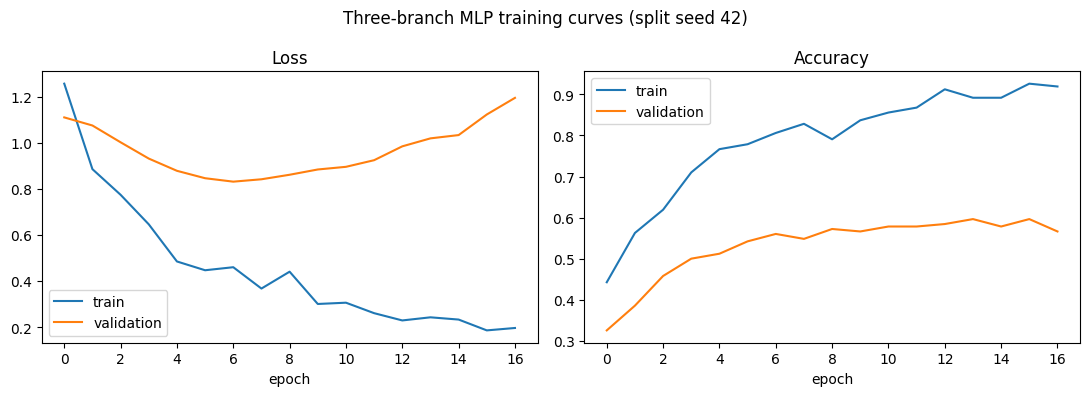


 MLP (3-branch) (pooled test predictions; participants can recur across splits)
              precision    recall  f1-score   support

          CN       0.62      0.77      0.69       263
         MCI       0.56      0.38      0.45       280
          AD       0.50      0.63      0.56        90

    accuracy                           0.58       633
   macro avg       0.56      0.59      0.56       633
weighted avg       0.57      0.58      0.56       633


 HAMF-style (pooled test predictions; participants can recur across splits)
              precision    recall  f1-score   support

          CN       0.57      0.60      0.59       263
         MCI       0.49      0.44      0.47       280
          AD       0.51      0.61      0.56        90

    accuracy                           0.53       633
   macro avg       0.53      0.55      0.54       633
weighted avg       0.53      0.53      0.53       633



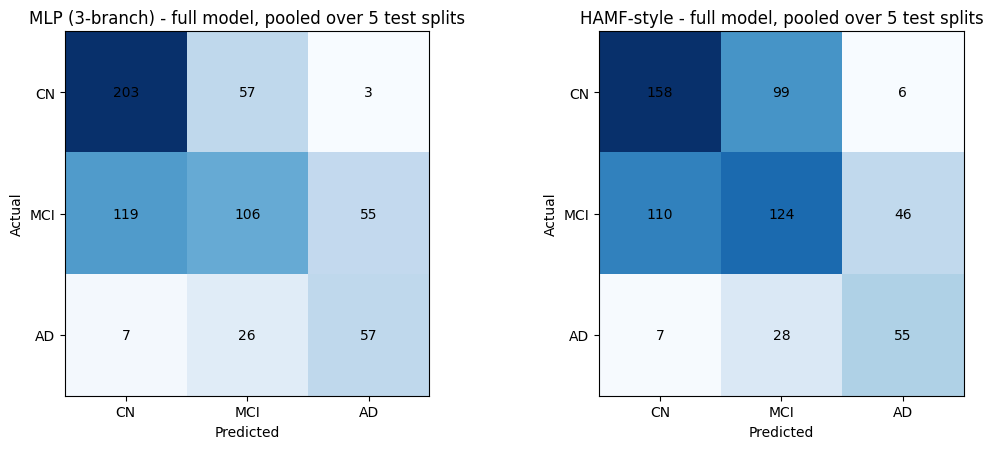

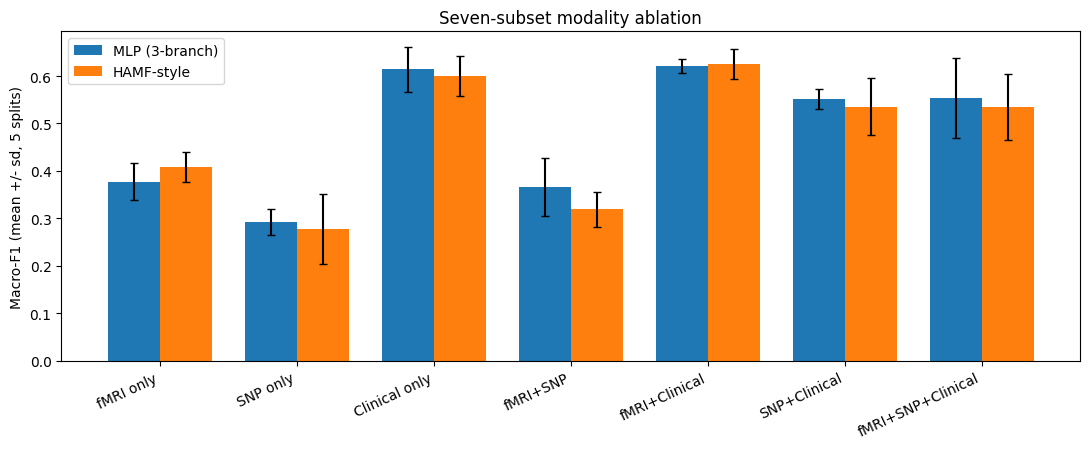

In [73]:
# ============================================================
# MODELS + MAIN EXPERIMENT
#   (1) three-branch MLP (methodology PDF, section 8)   (2) HAMF-style hierarchical attention (Lu et al. 2024)
#   7-subset modality ablation, 5 participant-level splits, mean +/- sd
# ============================================================
import tensorflow as tf
from tensorflow.keras import layers, Model, callbacks
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report)

def build_mlp(mods, dims):
    ins, reps = {}, []
    if "fmri" in mods:                                           # fMRI branch: 256 -> BN -> Drop .3 -> 128 -> 64
        i = layers.Input((dims["fmri"],), name="fmri"); h = layers.Dense(256, activation="relu")(i)
        h = layers.BatchNormalization()(h); h = layers.Dropout(0.30)(h)
        h = layers.Dense(128, activation="relu")(h); h = layers.Dense(64, activation="relu")(h); ins["fmri"] = i; reps.append(h)
    if "snp" in mods:                                            # SNP branch: 128 -> BN -> Drop .3 -> 64 -> 32
        i = layers.Input((dims["snp"],), name="snp"); h = layers.Dense(128, activation="relu")(i)
        h = layers.BatchNormalization()(h); h = layers.Dropout(0.30)(h)
        h = layers.Dense(64, activation="relu")(h); h = layers.Dense(32, activation="relu")(h); ins["snp"] = i; reps.append(h)
    if "clin" in mods:                                           # clinical branch: 64 -> BN -> Drop .2 -> 32
        i = layers.Input((dims["clin"],), name="clin"); h = layers.Dense(64, activation="relu")(i)
        h = layers.BatchNormalization()(h); h = layers.Dropout(0.20)(h)
        h = layers.Dense(32, activation="relu")(h); ins["clin"] = i; reps.append(h)
    z = reps[0] if len(reps) == 1 else layers.Concatenate()(reps)          # feature-level fusion
    z = layers.Dense(128, activation="relu")(z); z = layers.BatchNormalization()(z); z = layers.Dropout(0.40)(z)
    z = layers.Dense(64, activation="relu")(z); z = layers.Dropout(0.25)(z)
    return Model(inputs=ins, outputs=layers.Dense(K, activation="softmax")(z), name="three_branch_mlp")

@tf.keras.utils.register_keras_serializable(package="hamf")
class KeylessAttention(layers.Layer):
    """Eq. 2-5..2-7: e_i = w^T x_i ; lambda = softmax(e) ; output = sum_i lambda_i x_i"""
    def build(self, input_shape):
        self.w = self.add_weight(name="w", shape=(int(input_shape[-1]), 1), initializer="glorot_uniform", trainable=True)
        super().build(input_shape)
    def call(self, x):
        e = tf.tensordot(x, self.w, axes=[[2], [0]])
        lam = tf.nn.softmax(e, axis=1)
        return tf.reduce_sum(lam * x, axis=1)
    def compute_output_shape(self, input_shape): return (input_shape[0], input_shape[-1])

def build_hamf(mods, dims, d=64):
    ins, emb = {}, {}
    for name in mods:
        i = layers.Input((dims[name],), name=name); h = layers.Dense(128, activation="relu")(i)
        h = layers.BatchNormalization()(h); h = layers.Dropout(0.30)(h)
        h1 = layers.Dense(d)(h); gate = layers.Dense(d, activation="sigmoid")(h1)      # nonlinear gating (Eq. 2-4)
        ins[name] = i; emb[name] = layers.Multiply()([h1, gate])
    stack = lambda vs: layers.Concatenate(axis=1)([layers.Reshape((1, d))(v) for v in vs])
    att = lambda vs: KeylessAttention()(stack(vs))
    names = list(mods)
    if len(names) == 1: fused = emb[names[0]]
    elif len(names) == 2: fused = att([emb[names[0]], emb[names[1]]])                  # Eq. 2-12
    else:
        mg = att([emb["fmri"], emb["snp"]]); mc = att([emb["fmri"], emb["clin"]]); cg = att([emb["clin"], emb["snp"]])
        fused = att([mg, mc, cg])                                                      # Eq. 2-8..2-11
    z = layers.Dense(d // 2, activation="relu")(fused); z = layers.Dropout(0.25)(z)
    return Model(inputs=ins, outputs=layers.Dense(K, activation="softmax")(z), name="hamf_style")

def fit_eval(builder, mods, X, ytr, yva, yte, seed):
    """Adam 1e-3, batch 32, <=100 epochs, early stopping on val loss (patience 10), capped class weights."""
    tf.keras.utils.set_random_seed(seed)
    model = builder(mods, {k: X[k][0].shape[1] for k in mods})
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cls = np.unique(ytr); w = compute_class_weight("balanced", classes=cls, y=ytr)
    cw = {int(c): float(min(x, MAX_CLASS_WEIGHT)) for c, x in zip(cls, w)}
    for c in range(K): cw.setdefault(c, 1.0)
    es = callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    h = model.fit({k: X[k][0] for k in mods}, ytr, validation_data=({k: X[k][1] for k in mods}, yva),
                  epochs=100, batch_size=32, class_weight=cw, callbacks=[es], verbose=0)
    proba = model.predict({k: X[k][2] for k in mods}, verbose=0); pred = proba.argmax(1)
    present = np.unique(yte)
    auc = (roc_auc_score(label_binarize(yte, classes=list(range(K)))[:, present], proba[:, present], average="macro")
           if len(present) > 1 else np.nan)
    res = {"Accuracy": accuracy_score(yte, pred), "Balanced acc": balanced_accuracy_score(yte, pred),
           "Macro F1": f1_score(yte, pred, average="macro"), "ROC-AUC": auc}
    return res, pred, h.history, model

SUBSETS = {"fMRI only": ["fmri"], "SNP only": ["snp"], "Clinical only": ["clin"], "fMRI+SNP": ["fmri", "snp"],
           "fMRI+Clinical": ["fmri", "clin"], "SNP+Clinical": ["snp", "clin"], "fMRI+SNP+Clinical": ["fmri", "snp", "clin"]}
FULL = "fMRI+SNP+Clinical"

rows, pooled, split_info, keep = [], {}, [], {}
for seed in SEEDS:
    tr_ids, va_ids, te_ids = make_split(part, seed)
    assert not (tr_ids & va_ids) and not (tr_ids & te_ids) and not (va_ids & te_ids)       # zero participant overlap
    tr, va, te = [np.where(m["RID"].isin(s))[0] for s in (tr_ids, va_ids, te_ids)]
    ytr, yva, yte = m["y"].values[tr], m["y"].values[va], m["y"].values[te]
    split_info.append({"seed": seed, "train": len(tr), "val": len(va), "test": len(te),
                       "test_scans_per_class": {CLASS_LABELS[int(k)]: int(v) for k, v in zip(*np.unique(yte, return_counts=True))}})
    X = prep(tr, va, te, ytr)
    for fam, builder in [("MLP (3-branch)", build_mlp), ("HAMF-style", build_hamf)]:
        for sname, mods in SUBSETS.items():
            res, pred, hist, model = fit_eval(builder, mods, X, ytr, yva, yte, seed)
            rows.append({"Model": fam, "Inputs": sname, "seed": seed, **res})
            if sname == FULL:
                pooled.setdefault(fam, []).append((yte, pred))
                if seed == SEEDS[0]: keep[fam] = (hist, yte, pred)
            print(f"seed {seed} | {fam:15s} | {sname:18s} | acc {res['Accuracy']:.3f}  bacc {res['Balanced acc']:.3f}  F1 {res['Macro F1']:.3f}  AUC {res['ROC-AUC']:.3f}")
print("\nSplits:", json.dumps(split_info))

allres = pd.DataFrame(rows); allres.to_csv(OUTDIR / "mlp_hamf_all_runs.csv", index=False)
summ = allres.groupby(["Model", "Inputs"])[["Accuracy", "Balanced acc", "Macro F1", "ROC-AUC"]].agg(["mean", "std"]).round(3)
summ = summ.reindex(pd.MultiIndex.from_product([["MLP (3-branch)", "HAMF-style"], list(SUBSETS)]))
summ.to_csv(OUTDIR / "mlp_hamf_summary.csv"); display(summ)

# ---------------- figures + per-class report (pooled over the 5 test splits) ----------------
hist = keep["MLP (3-branch)"][0]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist["loss"], label="train"); ax[0].plot(hist["val_loss"], label="validation"); ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(hist["accuracy"], label="train"); ax[1].plot(hist["val_accuracy"], label="validation"); ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.suptitle("Three-branch MLP training curves (split seed %d)" % SEEDS[0]); plt.tight_layout()
plt.savefig(OUTDIR / "figures" / "mlp_training_curves.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for a, fam in zip(ax, ["MLP (3-branch)", "HAMF-style"]):
    yt = np.concatenate([p[0] for p in pooled[fam]]); yp = np.concatenate([p[1] for p in pooled[fam]])
    cm = confusion_matrix(yt, yp, labels=list(range(K))); a.imshow(cm, cmap="Blues")
    for i in range(K):
        for j in range(K): a.text(j, i, cm[i, j], ha="center", va="center")
    a.set_xticks(range(K)); a.set_yticks(range(K)); a.set_xticklabels(CLASS_LABELS); a.set_yticklabels(CLASS_LABELS)
    a.set_xlabel("Predicted"); a.set_ylabel("Actual"); a.set_title(f"{fam} - full model, pooled over {len(SEEDS)} test splits")
    print("\n", fam, "(pooled test predictions; participants can recur across splits)")
    print(classification_report(yt, yp, labels=list(range(K)), target_names=CLASS_LABELS, zero_division=0))
plt.tight_layout(); plt.savefig(OUTDIR / "figures" / "confusion_matrices.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(11, 4.6)); xs = np.arange(len(SUBSETS)); wd = 0.38
for off, fam in [(-wd / 2, "MLP (3-branch)"), (wd / 2, "HAMF-style")]:
    mu = [summ.loc[(fam, s), ("Macro F1", "mean")] for s in SUBSETS]; sdv = [summ.loc[(fam, s), ("Macro F1", "std")] for s in SUBSETS]
    ax.bar(xs + off, mu, wd, yerr=sdv, capsize=3, label=fam)
ax.set_xticks(xs); ax.set_xticklabels(list(SUBSETS), rotation=25, ha="right"); ax.set_ylabel("Macro-F1 (mean +/- sd, 5 splits)")
ax.set_title("Seven-subset modality ablation"); ax.legend(); plt.tight_layout()
plt.savefig(OUTDIR / "figures" / "ablation.png", dpi=150); plt.show()


## Fusion-strategy ablation

In [74]:
# ============================================================
# FUSION-STRATEGY ABLATION (HAMF paper, section 4.3): concatenate vs general attention vs hierarchical attention
# ============================================================
def build_fusion(mods, dims, mode, d=64):
    ins, emb = {}, {}
    for name in mods:
        i = layers.Input((dims[name],), name=name); h = layers.Dense(128, activation="relu")(i)
        h = layers.BatchNormalization()(h); h = layers.Dropout(0.30)(h); h1 = layers.Dense(d)(h)
        emb[name] = layers.Multiply()([h1, layers.Dense(d, activation="sigmoid")(h1)]) if mode in ("general", "ha_nonlinear") else h1
        ins[name] = i
    stack = lambda vs: layers.Concatenate(axis=1)([layers.Reshape((1, d))(v) for v in vs])
    att = lambda vs: KeylessAttention()(stack(vs))
    f, s, c = emb["fmri"], emb["snp"], emb["clin"]
    if mode == "concat": fused = layers.Concatenate()([f, s, c])
    elif mode == "general": fused = att([f, s, c])
    else: fused = att([att([f, s]), att([f, c]), att([c, s])])
    z = layers.Dropout(0.25)(layers.Dense(32, activation="relu")(fused))
    return Model(inputs=ins, outputs=layers.Dense(K, activation="softmax")(z))

MODES = {"Concatenate": "concat", "General attention": "general", "HA + linear gating": "ha_linear", "HA + nonlinear gating": "ha_nonlinear"}
frows = []
for seed in SEEDS:
    tr_ids, va_ids, te_ids = make_split(part, seed)
    tr, va, te = [np.where(m["RID"].isin(s))[0] for s in (tr_ids, va_ids, te_ids)]
    ytr, yva, yte = m["y"].values[tr], m["y"].values[va], m["y"].values[te]
    X = prep(tr, va, te, ytr)
    for lbl, mode in MODES.items():
        res, _, _, _ = fit_eval(lambda mods, dims, mode=mode: build_fusion(mods, dims, mode), SUBSETS[FULL], X, ytr, yva, yte, seed)
        frows.append({"Fusion": lbl, "seed": seed, **res})
        print(seed, lbl, {k: round(float(v), 3) for k, v in res.items()})
fres = pd.DataFrame(frows).groupby("Fusion")[["Accuracy", "Balanced acc", "Macro F1", "ROC-AUC"]].agg(["mean", "std"]).round(3)
fres = fres.reindex(list(MODES)); fres.to_csv(OUTDIR / "fusion_ablation.csv"); display(fres)


42 Concatenate {'Accuracy': 0.484, 'Balanced acc': 0.534, 'Macro F1': 0.507, 'ROC-AUC': 0.707}
42 General attention {'Accuracy': 0.532, 'Balanced acc': 0.545, 'Macro F1': 0.546, 'ROC-AUC': 0.736}
42 HA + linear gating {'Accuracy': 0.508, 'Balanced acc': 0.598, 'Macro F1': 0.503, 'ROC-AUC': 0.698}
42 HA + nonlinear gating {'Accuracy': 0.587, 'Balanced acc': 0.614, 'Macro F1': 0.606, 'ROC-AUC': 0.771}
7 Concatenate {'Accuracy': 0.463, 'Balanced acc': 0.458, 'Macro F1': 0.454, 'ROC-AUC': 0.612}
7 General attention {'Accuracy': 0.479, 'Balanced acc': 0.483, 'Macro F1': 0.468, 'ROC-AUC': 0.609}
7 HA + linear gating {'Accuracy': 0.504, 'Balanced acc': 0.491, 'Macro F1': 0.487, 'ROC-AUC': 0.67}
7 HA + nonlinear gating {'Accuracy': 0.43, 'Balanced acc': 0.432, 'Macro F1': 0.407, 'ROC-AUC': 0.63}
2024 Concatenate {'Accuracy': 0.534, 'Balanced acc': 0.591, 'Macro F1': 0.531, 'ROC-AUC': 0.728}
2024 General attention {'Accuracy': 0.568, 'Balanced acc': 0.637, 'Macro F1': 0.573, 'ROC-AUC': 0.738}
2

Accuracy        Balanced acc        Macro F1         \
                          mean    std         mean    std     mean    std   
Fusion                                                                      
Concatenate              0.503  0.030        0.527  0.052    0.502  0.035   
General attention        0.554  0.050        0.572  0.063    0.558  0.059   
HA + linear gating       0.546  0.068        0.592  0.076    0.550  0.079   
HA + nonlinear gating    0.531  0.060        0.550  0.073    0.536  0.078   

                      ROC-AUC         
                         mean    std  
Fusion                                
Concatenate             0.699  0.049  
General attention       0.718  0.063  
HA + linear gating      0.743  0.057  
HA + nonlinear gating   0.718  0.054

## Interpretability (SHAP)

  0%|          | 0/30 [00:00<?, ?it/s]

Share of mean |SHAP| by modality: {'fmri': 0.038, 'snp': 0.564, 'clin': 0.399}
MEM_minus_EXF        0.016022
COG_MIN              0.010445
rs2727905            0.009933
rs4823717            0.009827
PHC_Age_Diagnosis    0.009267
PHC_EXF_SE           0.008922
rs1980499            0.007832
kgp3822375           0.007391
PHC_LAN              0.007048
kgp22740325          0.006969
dtype: float64


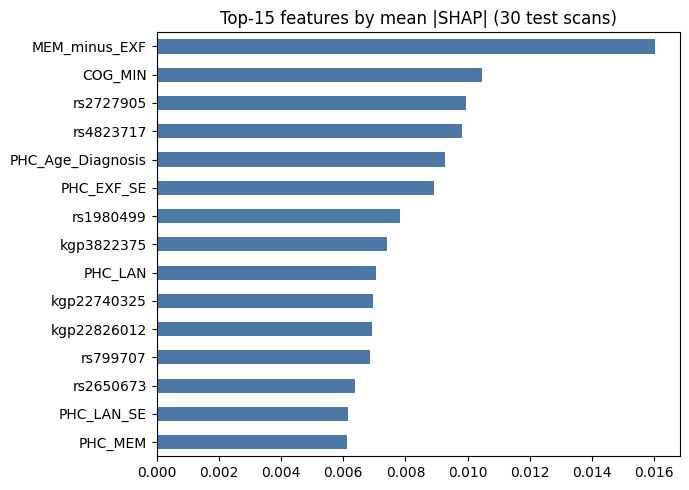

In [91]:
# ============================================================
# INTERPRETABILITY: SHAP on the full three-branch MLP (split seed 42)
# SHAP values are predictive associations within this model and cohort, not causal effects.
# ============================================================
try:
    import shap
except ImportError:
    shap = None
    print("shap is not installed -> run `!pip install shap` and re-run this cell")

if shap is not None:
    seed = SEEDS[0]; mods = SUBSETS[FULL]
    tr_ids, va_ids, te_ids = make_split(part, seed)
    tr, va, te = [np.where(m["RID"].isin(s))[0] for s in (tr_ids, va_ids, te_ids)]
    ytr, yva, yte = m["y"].values[tr], m["y"].values[va], m["y"].values[te]
    X = prep(tr, va, te, ytr)
    snp_names = list(SNP_SELECTED)
    _, _, _, model = fit_eval(build_mlp, mods, X, ytr, yva, yte, seed)
    sizes = [X[k][0].shape[1] for k in mods]
    def fpred(Zm):
        parts, c = {}, 0
        for k, s in zip(mods, sizes): parts[k] = Zm[:, c:c + s].astype("float32"); c += s
        return model.predict(parts, verbose=0)
    Ztr = np.hstack([X[k][0] for k in mods]); Zte = np.hstack([X[k][2] for k in mods])
    ex = shap.KernelExplainer(fpred, shap.kmeans(Ztr, 20))
    sv = ex.shap_values(Zte[:30], nsamples=200)
    sv = np.stack(sv, -1) if isinstance(sv, list) else sv
    names = []
    for k in mods: names += (FM if k == "fmri" else CLIN if k == "clin" else snp_names)
    imp = pd.Series(np.abs(sv).mean(axis=(0, 2)), index=names)
    c = 0; shap_share = {}
    for k, s in zip(mods, sizes):
        shap_share[k] = float(imp.iloc[c:c + s].sum() / imp.sum()); c += s
    print("Share of mean |SHAP| by modality:", {k: round(v, 3) for k, v in shap_share.items()})
    print(imp.sort_values(ascending=False).head(10))
    imp.sort_values().tail(15).plot.barh(figsize=(7, 5), color="#4C78A8"); plt.title("Top-15 features by mean |SHAP| (30 test scans)")
    plt.tight_layout(); plt.savefig(OUTDIR / "figures" / "shap_top15.png", dpi=150); plt.show()
    json.dump(shap_share, open(OUTDIR / "shap_modality_share.json", "w"), indent=2)


In [78]:
# ============================================================
# IMPROVEMENT 2: biologically motivated SNP features
#   APOE e4 / e2 allele counts + known AD-risk loci (extracted straight from the PLINK files)
#   Ancestry PCs are added later, INSIDE each training fold (see prep2).
# NOTE: rsIDs below are written from memory -> loci missing from your BIM are simply skipped and printed.
# ============================================================
import numpy as np, pandas as pd

RISK_RSIDS = ["rs6656401", "rs6733839", "rs10948363", "rs11771145", "rs9331896", "rs983392", "rs10792832",
              "rs4147929", "rs3865444", "rs11218343", "rs9271192", "rs28834970", "rs35349669", "rs190982",
              "rs10838725", "rs17125944", "rs7274581", "rs2075650"]
APOE_POS = {"rs429358": (45411941, 44908684), "rs7412": (45412079, 44908822)}   # chr19 (GRCh37, GRCh38) fallback
COMP = {"A": "T", "T": "A", "C": "G", "G": "C"}

# --- re-read the PLINK metadata here so this cell does not depend on notebook globals that may have been overwritten ---
bed_path = "/kaggle/input/datasets/ananya2323/snpdata/WGS_Omni25_BIN_wo_ConsentsIssues.bed"
bim = pd.read_csv(bed_path[:-4] + ".bim", sep=r"\s+", header=None, names=["CHR", "SNP", "CM", "BP", "A1", "A2"], dtype={"SNP": str, "A1": str, "A2": str})
fam = pd.read_csv(bed_path[:-4] + ".fam", sep=r"\s+", header=None, names=["FID", "IID", "PAT", "MAT", "SEX", "PHENO"])
n_samples = len(fam); bytes_per_variant = (n_samples + 3) // 4
decode_table = np.zeros((256, 4), dtype=np.uint8)
for b in range(256):
    for j in range(4): decode_table[b, j] = (b >> (2 * j)) & 3
code_to_dosage = np.array([0, 255, 1, 2], dtype=np.uint8)      # 00 -> 0, 01 -> missing, 10 -> 1, 11 -> 2
print("PLINK:", n_samples, "samples,", len(bim), "variants")

bim_idx = {}
for i, s in enumerate(bim["SNP"].astype(str).values):
    bim_idx.setdefault(s, i)
print("BIM IDs that look like rsIDs:", sum(s.startswith("rs") for s in bim_idx), "of", len(bim_idx))

def find_variant(rsid):
    if rsid in bim_idx:
        return bim_idx[rsid]
    if rsid in APOE_POS:                                           # position fallback (APOE only)
        for pos in APOE_POS[rsid]:
            hit = np.where((bim["CHR"].astype(str).values == "19") & (bim["BP"].values == pos))[0]
            if len(hit):
                return int(hit[0])
    return None

def read_variant_dosage(i):                                        # copies of A2 (same convention as earlier cells); NaN = missing
    with open(bed_path, "rb") as f:
        f.seek(3 + int(i) * bytes_per_variant)
        raw = np.frombuffer(f.read(bytes_per_variant), dtype=np.uint8)
    d = code_to_dosage[decode_table[raw].reshape(-1)[:n_samples]].astype(np.float32)
    d[d == 255] = np.nan
    return d

def allele_count(i, allele):                                       # copies of `allele` (handles strand flip and A1/A2 order)
    a1, a2 = str(bim.at[i, "A1"]), str(bim.at[i, "A2"])
    d = read_variant_dosage(i)
    for al in (allele, COMP[allele]):
        if al == a2: return d
        if al == a1: return 2 - d
    return None

risk_df = pd.DataFrame({"IID": fam["IID"].astype(str).values})
i429, i7412 = find_variant("rs429358"), find_variant("rs7412")
if i429 is not None:
    e4 = allele_count(i429, "C")
    if e4 is not None: risk_df["APOE_e4_count"] = e4                  # C at rs429358 = e4 allele
if i7412 is not None:
    e2 = allele_count(i7412, "T")
    if e2 is not None: risk_df["APOE_e2_count"] = e2                  # T at rs7412 = e2 allele
for r in RISK_RSIDS:
    if r in bim_idx:
        risk_df[r] = read_variant_dosage(bim_idx[r])

RISK_COLS = [c for c in risk_df.columns if c != "IID"]
print("APOE columns:", [c for c in RISK_COLS if c.startswith("APOE")] or "NOT FOUND -> check BIM ID format / build")
print("Risk loci found: %d of %d" % (sum(r in bim_idx for r in RISK_RSIDS), len(RISK_RSIDS)))
assert RISK_COLS, "No risk-locus SNPs found in the BIM; the 'snp_risk' variant cannot be built."

m = m.drop(columns=[c for c in RISK_COLS if c in m.columns]).merge(risk_df, on="IID", how="left").reset_index(drop=True)
print("m shape after merge:", m.shape, "| scans with APOE e4 value:",
      int(m["APOE_e4_count"].notna().sum()) if "APOE_e4_count" in m else 0)

PLINK: 812 samples, 2379855 variants
BIM IDs that look like rsIDs: 710764 of 2379855
APOE columns: NOT FOUND -> check BIM ID format / build
Risk loci found: 5 of 18
m shape after merge: (875, 5090) | scans with APOE e4 value: 0


In [86]:
# ============================================================
# IMPROVEMENTS 5, 6: repeated participant-grouped CV, training-only preprocessing, classical baselines
# ============================================================
import time
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score

QUICK = True                  # True -> 1 repeat, 3-seed ensemble (fast sanity pass)
N_SPLITS   = 5                 # outer folds (participant-grouped, stratified)
N_REPEATS  = 1 if QUICK else 2 # repeats with different fold assignments
ENSEMBLE_N = 3 if QUICK else 5 # MLP seeds averaged in the final stage
N_PCS      = 5                 # ancestry PCs (fitted on training scans only)

def eval_metrics(y, proba):
    pred = proba.argmax(1)
    try:    auc = roc_auc_score(y, proba, multi_class="ovr", average="macro", labels=list(range(K)))
    except Exception: auc = np.nan
    return dict(acc=accuracy_score(y, pred), bacc=balanced_accuracy_score(y, pred),
                f1=f1_score(y, pred, average="macro"), auc=auc)

def make_folds(repeat):
    sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=1000 + repeat)
    for fold, (trv, te) in enumerate(sgkf.split(m, m["y"].values, groups=m["RID"].values)):
        rng = np.random.default_rng(repeat * 100 + fold)
        rids = m["RID"].values[trv]
        prt = part.loc[np.unique(rids)]                            # participant-level labels
        va_r = set()
        for k in np.unique(prt.values):                            # ~15% of TRAIN participants per class -> validation
            g = prt.index.values[prt.values == k].copy(); rng.shuffle(g)
            if len(g) >= 3: va_r |= set(g[:max(1, round(0.15 * len(g)))])
        vmask = np.isin(rids, list(va_r))
        yield fold, trv[~vmask], trv[vmask], te

def prep2(tr, va, te):
    """Everything data-dependent is fitted on the TRAIN scans only."""
    y_tr = m["y"].values[tr]; out = {}
    for name, cols in [("fmri", FM), ("clin", CLIN)]:
        imp, sc = SimpleImputer(strategy="median"), StandardScaler()
        a = sc.fit_transform(imp.fit_transform(m.loc[tr, cols].values.astype("float32")))
        f = lambda idx, imp=imp, sc=sc, cols=cols: sc.transform(imp.transform(m.loc[idx, cols].values.astype("float32")))
        out[name] = [a, f(va), f(te)]
    # SNP variant A (original): top-K by F-test on train labels
    imp = SimpleImputer(strategy="median")
    Xs = imp.fit_transform(m.loc[tr, SN].values.astype("float32"))
    sel = SelectKBest(f_classif, k=min(K_SNP, Xs.shape[1])).fit(Xs, y_tr)
    sc = StandardScaler().fit(sel.transform(Xs))
    g = lambda idx: sc.transform(sel.transform(imp.transform(m.loc[idx, SN].values.astype("float32"))))
    out["snp_top50"] = [sc.transform(sel.transform(Xs)), g(va), g(te)]
    # SNP variant B (new): APOE + risk loci + ancestry PCs (PCA fitted on TRAIN pool genotypes; no labels used)
    scp = StandardScaler().fit(Xs); pca = PCA(n_components=N_PCS, random_state=0).fit(scp.transform(Xs))
    def blk(idx):
        pcs = pca.transform(scp.transform(imp.transform(m.loc[idx, SN].values.astype("float32"))))
        return np.hstack([m.loc[idx, RISK_COLS].values.astype("float32"), pcs])
    imp2, sc2 = SimpleImputer(strategy="median"), StandardScaler()
    a = sc2.fit_transform(imp2.fit_transform(blk(tr)))
    h = lambda idx: sc2.transform(imp2.transform(blk(idx)))
    out["snp_risk"] = [a, h(va), h(te)]
    return out

def run_baseline(kind, mods, X, ytr, seed=0):
    Xtr = np.hstack([X[k][0] for k in mods]); Xva = np.hstack([X[k][1] for k in mods]); Xte = np.hstack([X[k][2] for k in mods])
    if kind == "LogReg":
        clf = LogisticRegression(C=0.1, max_iter=3000, class_weight="balanced")
    else:
        clf = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, l2_regularization=1.0,
                                             class_weight="balanced", early_stopping=False, random_state=seed)
    clf.fit(Xtr, ytr)
    return clf.predict_proba(Xva), clf.predict_proba(Xte)

# ---- build all folds once (preprocessing is the slow part and is identical for every model) ----
t0 = time.time(); FOLDS = []
for rep in range(N_REPEATS):
    for fold, tr, va, te in make_folds(rep):
        FOLDS.append(dict(rep=rep, fold=fold, seed=rep * 10 + fold, X=prep2(tr, va, te),
                          ytr=m["y"].values[tr], yva=m["y"].values[va], yte=m["y"].values[te]))
print("folds built: %d (%.0fs) | per-fold sizes (train/val/test scans): %s" % (
    len(FOLDS), time.time() - t0, [(len(f["ytr"]), len(f["yva"]), len(f["yte"])) for f in FOLDS[:3]]))
print("SNP-risk feature count:", FOLDS[0]["X"]["snp_risk"][0].shape[1], "| top-50 count:", FOLDS[0]["X"]["snp_top50"][0].shape[1])


folds built: 5 (3s) | per-fold sizes (train/val/test scans): [(621, 94, 160), (605, 111, 159), (608, 91, 176)]
SNP-risk feature count: 10 | top-50 count: 50


In [87]:
# ============================================================
# IMPROVEMENTS 1, 4, 7: smaller / regularised MLP, modality dropout, auxiliary heads, seed ensemble
# Architecture follows the PDF (section 8); `width`, `l2`, `mod_drop`, `aux` are the only knobs added.
# ============================================================
import tensorflow as tf
from tensorflow.keras import layers, Model, callbacks, regularizers

def build_mlp2(mods, dims, width=1.0, l2=0.0, mod_drop=0.0, aux=0.0):
    w   = lambda n: max(4, int(round(n * width)))
    reg = regularizers.l2(l2) if l2 > 0 else None
    D   = lambda n: layers.Dense(n, activation="relu", kernel_regularizer=reg)
    spec = {"fmri": ([256, 128, 64], 0.30), "snp": ([128, 64, 32], 0.30), "clin": ([64, 32], 0.20)}
    ins, reps = {}, []
    for name in mods:
        sizes, dr = spec[name]
        i = layers.Input((dims[name],), name=name)
        h = D(w(sizes[0]))(i); h = layers.BatchNormalization()(h); h = layers.Dropout(dr)(h)
        for s in sizes[1:]: h = D(w(s))(h)
        ins[name] = i; reps.append((name, h))
    multi = len(mods) > 1
    aux_out = {f"aux_{n}": layers.Dense(K, activation="softmax", name=f"aux_{n}")(h) for n, h in reps} if (multi and aux > 0) else {}
    if multi and mod_drop > 0:                                     # drop a whole branch per sample (rescaled)
        reps = [(n, layers.Dropout(mod_drop, noise_shape=(None, 1))(h)) for n, h in reps]
    z = reps[0][1] if not multi else layers.Concatenate()([h for _, h in reps])
    z = D(w(128))(z); z = layers.BatchNormalization()(z); z = layers.Dropout(0.40)(z)
    z = D(w(64))(z);  z = layers.Dropout(0.25)(z)
    main = layers.Dense(K, activation="softmax", name="main")(z)
    # Keras 3 needs the output structure to match loss / y / sample_weight: a single tensor, or a dict keyed by output name
    return Model(inputs=ins, outputs=({"main": main, **aux_out} if aux_out else main), name="three_branch_mlp_v2")

def _main_proba(p):
    if isinstance(p, dict): return p["main"]
    if isinstance(p, (list, tuple)): return p[0]
    return p

def fit_once(mods, X, ytr, yva, seed, cfg):
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
    model = build_mlp2(mods, {k: X[k][0].shape[1] for k in mods}, **cfg)
    has_aux = len(model.outputs) > 1
    names = ["main"] + [f"aux_{k}" for k in mods] if has_aux else None
    if has_aux:
        loss = {n: "sparse_categorical_crossentropy" for n in names}
        lw   = {n: (1.0 if n == "main" else cfg["aux"]) for n in names}
        model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=loss, loss_weights=lw)
    else:
        model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy")
    cls = np.unique(ytr); wts = compute_class_weight("balanced", classes=cls, y=ytr)
    cw  = {int(c): float(min(x, MAX_CLASS_WEIGHT)) for c, x in zip(cls, wts)}
    sw  = np.array([cw.get(int(c), 1.0) for c in ytr], dtype="float32")
    xtr = {k: X[k][0] for k in mods}; xva = {k: X[k][1] for k in mods}
    if has_aux:
        y_t = {n: ytr for n in names}; y_v = {n: yva for n in names}; sw = {n: sw for n in names}
    else:
        y_t, y_v = ytr, yva
    es = callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    model.fit(xtr, y_t, sample_weight=sw, validation_data=(xva, y_v), epochs=100, batch_size=32,
              callbacks=[es], verbose=0)
    return model

def fit_ensemble(mods, X, ytr, yva, yte, seed, cfg, n=1):
    """Returns (val proba, test proba) averaged over n seeds, and the first single model's test proba."""
    pv, pt = [], []
    for j in range(n):
        mdl = fit_once(mods, X, ytr, yva, seed * 100 + j, cfg)
        pv.append(_main_proba(mdl.predict({k: X[k][1] for k in mods}, verbose=0)))
        pt.append(_main_proba(mdl.predict({k: X[k][2] for k in mods}, verbose=0)))
    return np.mean(pv, 0), np.mean(pt, 0), pt[0]

In [89]:
# ============================================================
# FAST RUN (~25 MLP fits): fixed config, 5 folds, 3 key subsets, single seed
# ============================================================
SUBSETS2 = {"Clinical only": ["clin"], "fMRI+Clinical": ["fmri", "clin"], "fMRI+SNP+Clinical": ["fmri", "snp", "clin"]}
FULL = "fMRI+SNP+Clinical"
CONFIGS = {"PDF baseline": dict(width=1.00, l2=0.0, mod_drop=0.0, aux=0.0)}
best_cfg_name, best_variant = "half + L2 + modality-drop", "snp_risk"
best_cfg = dict(width=0.50, l2=1e-3, mod_drop=0.3, aux=0.0)
FOLDS_RUN = FOLDS[:5]

rows = []
def log(stage, model, subset, fo, pv, pt):
    mv, mt = eval_metrics(fo["yva"], pv), eval_metrics(fo["yte"], pt)
    rows.append(dict(stage=stage, model=model, subset=subset, repeat=fo["rep"], fold=fo["fold"],
                     **{f"val_{k}": v for k, v in mv.items()}, **{f"test_{k}": v for k, v in mt.items()}))

def with_snp(fo, variant):
    X = dict(fo["X"]); X["snp"] = fo["X"][variant]; return X

t0 = time.time()
for n_f, fo in enumerate(FOLDS_RUN):
    X_new, X_old = with_snp(fo, best_variant), with_snp(fo, "snp_top50")
    for sname, mods in SUBSETS2.items():
        pv, pt, _ = fit_ensemble(mods, X_old, fo["ytr"], fo["yva"], fo["yte"], fo["seed"], CONFIGS["PDF baseline"], n=1)
        log("final", "A. PDF baseline (original SNP top-50)", sname, fo, pv, pt)
        pv, pt, _ = fit_ensemble(mods, X_new, fo["ytr"], fo["yva"], fo["yte"], fo["seed"], best_cfg, n=1)
        log("final", "B. improved MLP (fixed config, new SNP features)", sname, fo, pv, pt)
        for kind in ["LogReg", "GradBoost"]:
            bv, bt = run_baseline(kind, mods, X_new, fo["ytr"], seed=fo["seed"])
            log("final", f"D. {kind} (same features)", sname, fo, bv, bt)
    print("fold %d/%d done (%.0fs elapsed)" % (n_f + 1, len(FOLDS_RUN), time.time() - t0))

fold 1/5 done (111s elapsed)
fold 2/5 done (233s elapsed)
fold 3/5 done (353s elapsed)
fold 4/5 done (479s elapsed)
fold 5/5 done (604s elapsed)


In [90]:
# ============================================================
# SUMMARY: mean +/- sd over outer folds (test data of each fold; never used for any choice above)
# ============================================================
RES = pd.DataFrame(rows)
RES.to_csv(OUTDIR / "improvement_all_runs.csv", index=False)
F = RES[RES.stage == "final"]
agg = F.groupby(["subset", "model"])[["test_acc", "test_bacc", "test_f1", "test_auc"]].agg(["mean", "std"]).round(3)
agg.to_csv(OUTDIR / "improvement_summary.csv")
print("Macro-F1 (mean over folds):")
print(F.pivot_table(index="model", columns="subset", values="test_f1", aggfunc="mean")[list(SUBSETS2)].round(3).to_string())
print("\nAccuracy (mean over folds):")
print(F.pivot_table(index="model", columns="subset", values="test_acc", aggfunc="mean")[list(SUBSETS2)].round(3).to_string())

print("\nFull 3-modality model, all metrics (mean +/- sd over %d folds):" % F[F.subset == FULL].groupby("model").size().iloc[0])
print(agg.loc[FULL].to_string())

# paired comparison against the PDF baseline, fold by fold (folds overlap, so treat as indicative, not a formal test)
base = F[F.model.str.startswith("A.")].set_index(["subset", "repeat", "fold"])
print("\nPaired gain vs. A. PDF baseline (macro-F1, same folds):  mean diff | folds improved")
for mdl in sorted(F.model.unique()):
    if mdl.startswith("A."): continue
    cur = F[F.model == mdl].set_index(["subset", "repeat", "fold"])
    d = (cur["test_f1"] - base["test_f1"]).dropna()
    for sname in [FULL, "Clinical only", "fMRI+Clinical"]:
        dd = d.xs(sname, level="subset")
        print("  %-38s %-18s %+.3f | %d/%d" % (mdl, sname, dd.mean(), (dd > 0).sum(), len(dd)))


Macro-F1 (mean over folds):
subset                                            Clinical only  fMRI+Clinical  fMRI+SNP+Clinical
model                                                                                            
A. PDF baseline (original SNP top-50)                     0.638          0.617              0.581
B. improved MLP (fixed config, new SNP features)          0.616          0.601              0.600
D. GradBoost (same features)                              0.642          0.648              0.649
D. LogReg (same features)                                 0.621          0.637              0.650

Accuracy (mean over folds):
subset                                            Clinical only  fMRI+Clinical  fMRI+SNP+Clinical
model                                                                                            
A. PDF baseline (original SNP top-50)                     0.665          0.639              0.597
B. improved MLP (fixed config, new SNP features)          0.6

## Save results

In [92]:
# ============================================================
# SAVE RESULTS SUMMARY + README + ZIP
# ============================================================
import zipfile
def md(df):
    d = df.copy(); d.columns = [" ".join(str(x) for x in c).strip() if isinstance(c, tuple) else str(c) for c in d.columns]
    d = d.reset_index()
    return "| " + " | ".join(map(str, d.columns)) + " |\n|" + "---|" * len(d.columns) + "\n" + "\n".join("| " + " | ".join(str(v) for v in r) + " |" for r in d.values)
(OUTDIR / "README.md").write_text(f"""# Multimodal Alzheimer's diagnosis classification (fMRI + SNP + clinical, ADNI)

Three-class task (CN / MCI / AD, harmonised PHC diagnosis codes 1/2/3) on {len(m)} fMRI scans from {m.RID.nunique()} participants.
Methodology: three-branch MLP with feature-level fusion, and a HAMF-style hierarchical-attention model (after Lu et al., 2024).

## Cohort and design
- Scans are matched to clinical/cognitive records by participant and visit, with a maximum gap of {MAX_GAP_DAYS} days.
- Participant-level 70/15/15 splits (5 seeds); imputation, scaling and SNP selection are fitted on training participants only.
- fMRI: {len(FM)} unique precomputed default-mode-network connectivity features. SNP: QC + LD pruning, top {K_SNP} per training split. Clinical: {len(CLIN)} features.
- EMCI/LMCI labels are not available in the supplied files, so the task is 3-class, not 4-class.

## Results (mean +/- sd over 5 participant-level splits)
{md(summ)}

### Fusion strategies (full model)
{md(fres)}

## Caveats
- Cognitive composite scores partly define diagnosis, so clinical-containing models are expected to dominate.
- Small test sets (AD has few participants): differences of a few points are within noise.
- Simplifications versus the HAMF paper: no SDAE pre-training, ANOVA F-test SNP selection, precomputed fMRI features instead of CNN MRI features; the task differs (diagnosis, not sMCI-vs-pMCI conversion), so published numbers are not comparable.
- A GCN comparison (methodology PDF section 14) was not implemented.
- Research model only; not a validated diagnostic tool. ADNI data are not redistributed.
""")
zp = OUTDIR.parent / "outputs.zip"
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
    for p in OUTDIR.rglob("*"):
        if p.is_file(): z.write(p, p.relative_to(OUTDIR))
print("Saved:", sorted(str(p.relative_to(OUTDIR)) for p in OUTDIR.rglob("*") if p.is_file())); print("Zip:", zp)


Saved: ['.gitignore', 'README.md', 'cohort_flow.json', 'example_input_template.csv', 'figures/ablation.png', 'figures/ablation_mlp_vs_hamf.png', 'figures/confusion_matrices.png', 'figures/confusion_matrices_mlp_hamf.png', 'figures/error_analysis.png', 'figures/feature_importance.png', 'figures/mlp_training_curves.png', 'figures/shap_top15.png', 'fusion_ablation.csv', 'improvement_all_runs.csv', 'improvement_summary.csv', 'leakage_audit.json', 'metrics.json', 'mlp_hamf_all_runs.csv', 'mlp_hamf_all_runs_v2.csv', 'mlp_hamf_summary.csv', 'mlp_hamf_summary_v2.csv', 'mlp_three_branch.keras', 'mlp_tuning_all_runs.csv', 'model.joblib', 'model_card.json', 'model_comparison.csv', 'predict.py', 'requirements.txt', 'shap_modality_share.json']
Zip: /kaggle/working/outputs.zip
